## Analysis contexts

**Common cohort (N=110) provides the matched basis for cross-modality predictive comparison.** Full availability (N=112) preserves the modality-specific results. The two contexts are compared section by section. Model families are selected by mean inner-CV macro-F1, not outer-test performance. Differences cannot be attributed solely to sample size because preprocessing and search spaces also differ.

Training is disabled by default; reporting cells load the saved common-cohort results.

In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

from pathlib import Path as P110Path
import sys as p110_sys
import pandas as p110_pd
from IPython.display import display, Image as P110Image, Markdown as P110Markdown
p110_repo = next(p for p in [P110Path.cwd(), *P110Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(p110_repo) not in p110_sys.path:
    p110_sys.path.insert(0, str(p110_repo))
from scripts.OligoPolyThesis.utils_ml_oligopoly import load_primary110, _primary110_reporting_CONFIG as P110_CONFIG
p110_root = P110Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison')
p110_bundle = load_primary110(p110_root)

p110_config = 'mutation'
p110_output = p110_root / 'primary_110' / p110_config
p110_context = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_context_comparison.csv')
p110_context['analysis_context'] = ['Full availability (N=112)', 'Common cohort (N=110)']
p110_secondary_label, p110_primary_label = 'Full availability (N=112)', 'Common cohort (N=110)'
p110_folder, p110_prefix, p110_secondary_family, *_ = P110_CONFIG[p110_config]
p110_primary_family = p110_context.iloc[1].selected_family

from scripts.OligoPolyThesis.utils_ml_oligopoly import display_interpretation



# Mutation Data Modelling with Nested Cross-Validation

This notebook trains and evaluates predictive models using the final quality-controlled mutation dataset generated after preprocessing and QC.

## Input

- `20260505-mcpp-breast-mutation-all-metastatic-data-preprocessing-qc-final.csv`: final quality-controlled mutation dataset after preprocessing, rare-feature filtering, and redundancy reduction.

## Objective

The goal is to predict whether a patient belongs to the oligometastatic or polymetastatic cohort using mutation features only.

The target variable is encoded as:

* `0` = oligometastatic;
* `1` = polymetastatic.

## Models

The following candidate model families are evaluated:

* Logistic Regression with L1 regularization (`logreg_l1`);
* Random Forest (`random_forest`);
* XGBoost classifier (`xgboost`).

L2-regularized logistic regression is not included in this mutation modelling workflow because the mutation feature space is high-dimensional and L2 regularization does not perform explicit feature selection. Since the analysis includes gene-level biological interpretation, models that either provide sparse feature selection or feature-importance rankings were prioritised.

For logistic regression and random forest models, class weighting is included in the hyperparameter grid. This allows the inner cross-validation loop to compare default class weights against class-balanced alternatives.

For XGBoost, class imbalance is handled through the `scale_pos_weight` hyperparameter, calculated as the ratio between the number of oligometastatic and polymetastatic samples. The inner cross-validation loop compares the default value against this imbalance-adjusted value.

## Validation Strategy

Nested cross-validation is used to evaluate model performance while tuning hyperparameters.

- Outer cross-validation is used for out-of-training performance estimation;
- Inner cross-validation is used for hyperparameter tuning.

Hyperparameter selection is performed using macro F1-score within the inner cross-validation loop.

For each candidate model family, hyperparameters are selected using only the training data from each outer fold. The selected predictive model family is chosen according to the mean inner-cross-validation score across outer folds.

Outer-fold test metrics are used only to estimate out-of-training performance for each modelling strategy.

## Outputs

This notebook generates and saves the following files:

### Nested cross-validation outputs

* `mutation_nested_cv_predictions_reviewed.csv`: sample-level predictions from the outer test folds;
* `mutation_nested_cv_test_results_reviewed.csv`: fold-level test performance results;
* `mutation_nested_cv_train_results_reviewed.csv`: fold-level train performance results;
* `mutation_train_test_comparison_reviewed.csv`: side-by-side comparison of mean train and test performance;
* `mutation_model_selection_summary_reviewed.csv`: model selection summary based on mean inner-cross-validation score.

### Output filenames

Reports use `_reviewed.csv`.


### Evaluation and methodological limitations

Upstream filtering is not re-estimated inside this notebook's CV, and the XGBoost ratio uses complete-cohort labels. The analysis therefore does not evaluate a fully nested raw-data pipeline. A globally selected family's OOF result also lacks independent validation of that additional selection step.


In [1]:
import os
import sys
import pandas as pd
import json

from pathlib import Path
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt


## Import Utility Functions

All modelling and plotting helpers are imported from the thesis-specific `scripts.OligoPolyThesis/utils_ml_oligopoly.py`.


In [2]:
# ── Project root setup ───────────────────────────────────────────────────
ROOT = Path.cwd()
while not (ROOT / "scripts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    build_models_mutation,
    run_nested_cv_with_predictions_mutation,
    parse_best_params_mutation,
    plot_train_test_boxplots_mutation,
    plot_calibration_curve,
    run_nested_cv_with_flaml_mutation,
    mutation_outer_splits,
    validate_mutation_oof,
    mutation_pooled_oof_metrics,
    rank_mutation_inner_scores,
    mutation_flaml_settings,
    tune_full_cohort_flaml_mutation,
    extract_fitted_flaml_gene_rankings_mutation,
    plot_roc_curves,
    plot_confusion_matrix,
    plot_combined_ranking,
    plot_precision_recall_curves,
)
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    extract_selected_hyperparameters,
    plot_thesis_saved_figure,
)

## Mutation dataset

The input is the final dataset from mutation preprocessing and quality control.

In [ ]:
# Input data path
data_path_directory = "/mnt/data3/MCPP-Breast/Mutation-Data/"
input_file = "20260505-mcpp-breast-mutation-all-metastatic-data-preprocessing-qc-final.csv"
file_path = os.path.join(data_path_directory, input_file)

# Output path for modeling results
output_dir = "/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data"
os.makedirs(output_dir, exist_ok=True)

df_mutation = pd.read_csv(file_path)

thesis_print("Input file:", input_file)
thesis_print("Mutation dataset shape:", df_mutation.shape)

## Define Target and Predictor Matrix

The target variable is derived from `mutation_source`:
- `oligo` = 0
- `poly` = 1

The predictor matrix excludes:
- `sample_id`, because it is only an identifier;
- `mutation_source`, because it is used to define the target and must not be included as a predictor.

In [4]:
df_mutation = df_mutation.copy().assign(
    target=df_mutation["mutation_source"].map({"oligo": 0, "poly": 1})
)

sample_ids = df_mutation["sample_id"]

X = df_mutation.drop(columns=["sample_id", "mutation_source", "target"])
y = df_mutation["target"]

thesis_print("X shape:", X.shape)
thesis_print("y distribution:")
thesis_print(y.value_counts())

X shape: (112, 4552)
y distribution:
target
1    68
0    44
Name: count, dtype: int64


### Cohort comparison

Full availability retains the patients available to the modality. The common-cohort comparison uses identical patient membership and frozen outer-fold assignments across all seven inputs.

In [2]:
thesis_display(p110_pd.DataFrame([
    {'Context': p110_secondary_label, 'N': 112, 'Oligometastatic': 44, 'Polymetastatic': 68},
    {'Context': p110_primary_label, 'N': 110, 'Oligometastatic': 43, 'Polymetastatic': 67},
]))
thesis_display(p110_pd.crosstab(p110_bundle['cohort'].outer_fold, p110_bundle['cohort'].y_true).rename(columns={0:'Oligometastatic',1:'Polymetastatic'}))

,Context,N,Oligometastatic,Polymetastatic
0,Full availability (N=112),112,44,68
1,Common cohort (N=110),110,43,67


y_true,Oligometastatic,Polymetastatic
outer_fold,,
1,8,14
2,8,14
3,9,13
4,9,13
5,9,13


## Define Nested Cross-Validation Strategy

We use:
- **5-fold stratified outer CV** for model evaluation;
- **5-fold stratified inner CV** for hyperparameter tuning.

Stratification is used to preserve class proportions across folds.

In [5]:
RANDOM_STATE = 42

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SELECTION_SCORING = "f1_macro"
outer_splits = mutation_outer_splits(outer_cv, X, y)
RUN_NESTED_CV = False
RUN_FLAML = False
RUN_FULL_COHORT_FLAML = False
FLAML_TIME_BUDGET_SECONDS = 120  # Set an explicit positive per-search budget before FLAML.
coefficient_threshold = 1e-8



## Define Candidate Models and Hyperparameter Grids

We build the candidate mutation-based models using the utility script.

We compare three model families:

* Logistic Regression with L1 regularization;
* Random Forest;
* XGBoost.

L2-regularized logistic regression was removed from the mutation modelling workflow because the mutation feature space is high-dimensional and L2 regularization does not perform explicit feature selection.

For logistic regression and Random Forest, class weighting is treated as a hyperparameter in the inner cross-validation loop. For XGBoost, `scale_pos_weight` is calculated once from the complete N=112 modelling cohort and then passed to the candidate model grid. This is part of the original full-availability workflow and differs from the later common-cohort (N=110) analysis, where class weighting is determined within the training data.



In [6]:
# Compute class-imbalance ratio for XGBoost

n_negative = (y == 0).sum()
n_positive = (y == 1).sum()

xgb_scale_pos_weight = n_negative / n_positive

thesis_print("Number of oligometastatic samples (class 0):", n_negative)
thesis_print("Number of polymetastatic samples (class 1):", n_positive)
thesis_print("XGBoost scale_pos_weight:", xgb_scale_pos_weight)

models = build_models_mutation(
    random_state=RANDOM_STATE,
    xgb_scale_pos_weight=xgb_scale_pos_weight
)

thesis_print("Candidate models:")
thesis_print(list(models.keys()))

Number of oligometastatic samples (class 0): 44
Number of polymetastatic samples (class 1): 68
XGBoost scale_pos_weight: 0.6470588235294118
Candidate models:
['logreg_l1', 'random_forest', 'xgboost']


## Run Nested Cross-Validation and Store Feature Rankings

We run nested cross-validation to estimate out-of-training model performance and tune hyperparameters.

For each model and outer fold, the inner cross-validation loop selects the best hyperparameters using `GridSearchCV` and only the corresponding outer-training data. The selected estimator is then evaluated on the held-out outer test fold.

Outer-fold test metrics are used only to estimate performance, not to select the final predictive model.

In addition to train and test metrics and sample-level predictions, this function also stores fold-level feature rankings from the fitted model selected in each outer fold. For logistic regression models, these rankings are based on coefficients. For tree-based models, they are based on feature importances.

Saving these feature rankings during nested cross-validation avoids refitting the models later only to recover coefficients or feature importances.

In [7]:
manual_result_names = [
    "mutation_nested_cv_test_results", "mutation_nested_cv_train_results",
    "mutation_nested_cv_predictions", "mutation_nested_cv_feature_rankings",
]
manual_reviewed_paths = [Path(output_dir) / f"{name}_reviewed.csv" for name in manual_result_names]
if RUN_NESTED_CV:
    results_test_df, results_train_df, predictions_df, feature_rankings_df = run_nested_cv_with_predictions_mutation(
        X=X, y=y, sample_ids=sample_ids, models=models, outer_cv=outer_splits,
        inner_cv=inner_cv, scoring=SELECTION_SCORING, n_jobs=-1,
        coefficient_threshold=1e-8, top_n_tree=20,
    )
    for table, path in zip([results_test_df, results_train_df, predictions_df, feature_rankings_df], manual_reviewed_paths):
        table.to_csv(path, index=False)
else:
    if any(path.exists() for path in manual_reviewed_paths) and not all(path.exists() for path in manual_reviewed_paths):
        raise ValueError("Incomplete revised manual result bundle; do not mix revised and historical files.")
    manual_load_paths = manual_reviewed_paths if all(path.exists() for path in manual_reviewed_paths) else [
        Path(output_dir) / f"{name}.csv" for name in manual_result_names
    ]
    results_test_df, results_train_df, predictions_df, feature_rankings_df = [pd.read_csv(path) for path in manual_load_paths]



=== Running model: logreg_l1 ===
Outer fold 1/5


Outer fold 2/5
Outer fold 3/5
Outer fold 4/5
Outer fold 5/5

=== Running model: random_forest ===
Outer fold 1/5
Outer fold 2/5
Outer fold 3/5
Outer fold 4/5
Outer fold 5/5

=== Running model: xgboost ===
Outer fold 1/5
Outer fold 2/5
Outer fold 3/5
Outer fold 4/5
Outer fold 5/5


### Validated pooled out-of-fold reporting

Each model must contribute exactly one held-out prediction per unique sample_id, with labels and outer-fold membership matching the cohort and frozen splits. sample_id is the available subject identifier; multiple samples per patient would require a separate patient mapping. Pooled metrics concatenate outer-test predictions, whereas fold means average separately calculated metrics. Sensitivity/recall refers to polymetastatic disease; specificity refers to oligometastatic disease. Average precision summarises the precision–recall curve; Brier score measures overall probability error, not calibration alone.

The per-fold ROC/PR plots and per-family confusion matrices are separate comparison diagnostics. Pooled performance is descriptive and is never used for model selection.


,model,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,n_subjects
0,logreg_l1,0.616,0.510,0.510,0.615,0.588,0.432,0.745,0.232,112
1,random_forest,0.572,0.552,0.546,0.655,0.559,0.545,0.729,0.245,112
2,xgboost,0.538,0.527,0.526,0.627,0.691,0.364,0.695,0.263,112


--- Plotting ROC Curve ---


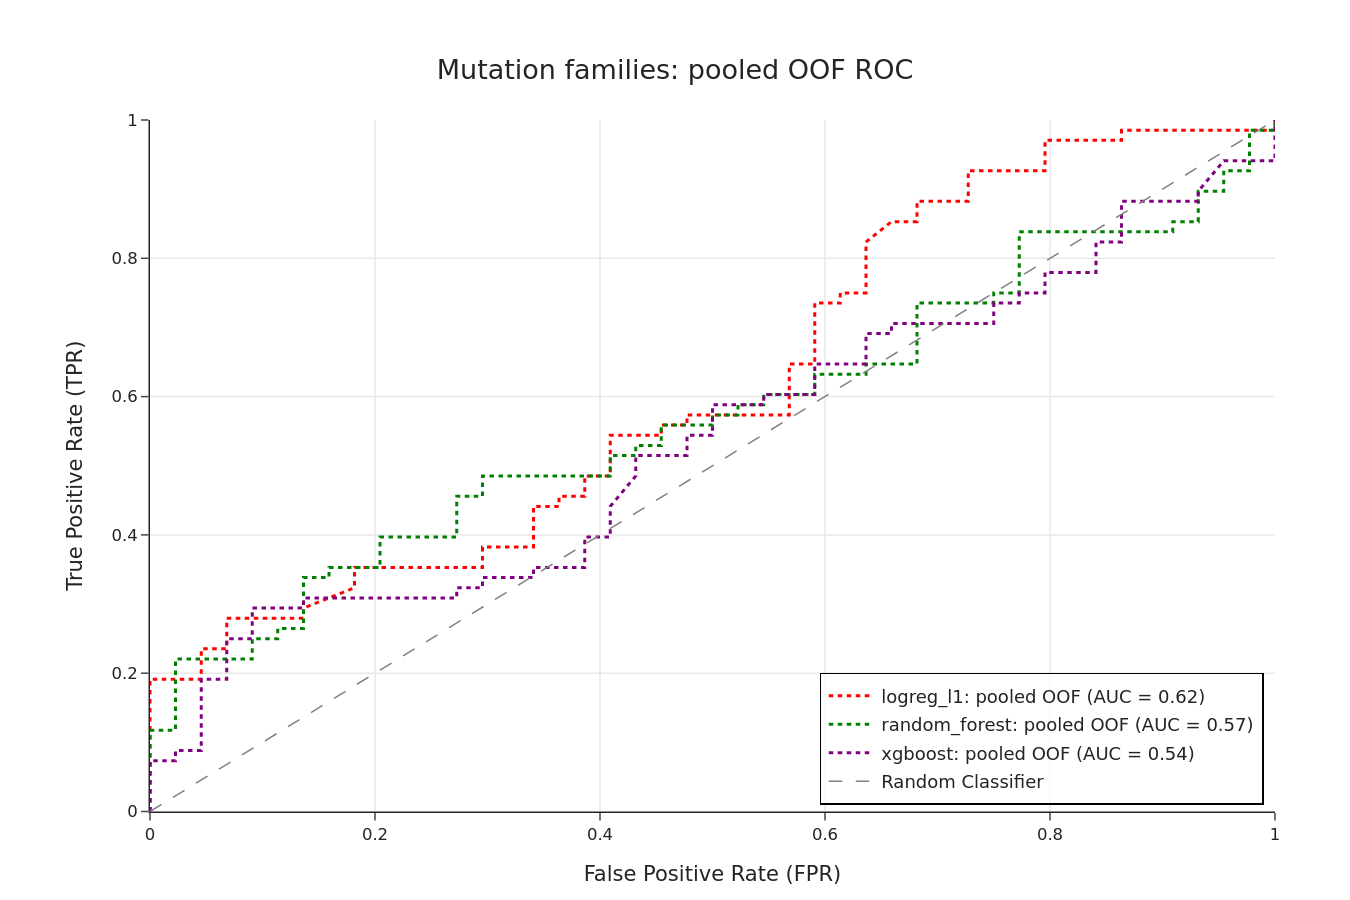

--- Plotting Precision–Recall Curve ---


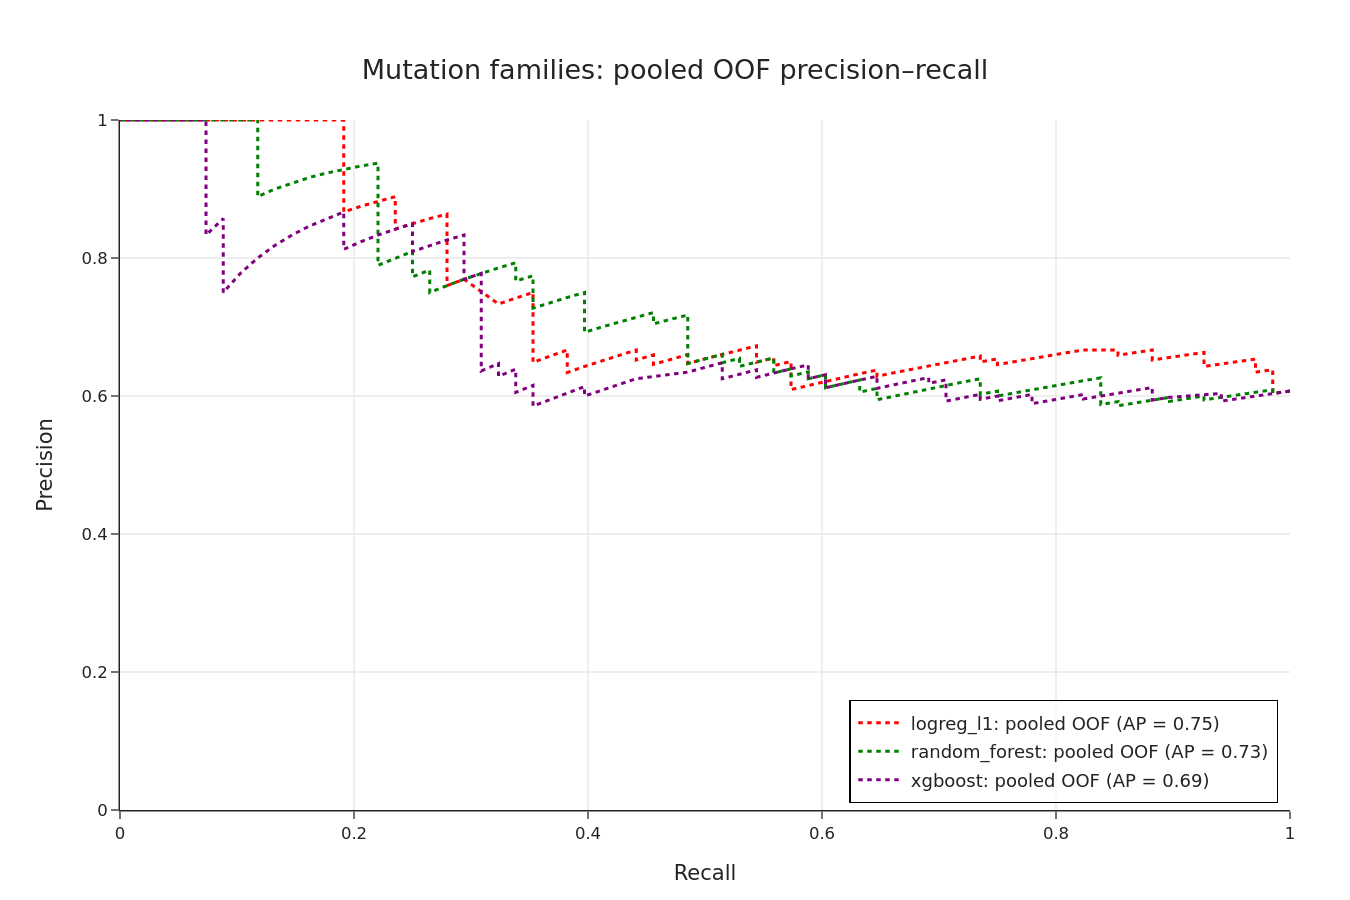

In [8]:
validated_oof_by_model = {
    name: validate_mutation_oof(predictions_df, name, df_mutation, outer_splits)
    for name in models
}
pooled_oof_metrics_df = pd.DataFrame([
    {"model": name, **mutation_pooled_oof_metrics(frame), "n_subjects": len(frame)}
    for name, frame in validated_oof_by_model.items()
])
thesis_display(pooled_oof_metrics_df)
pooled_oof_metrics_df.to_csv(Path(output_dir) / "mutation_pooled_oof_metrics_reviewed.csv", index=False)
pooled_curves = [{"y_true": frame.y_true, "y_prob": frame.y_proba,
                  "label": f"{name}: pooled OOF", "is_main_curve": False}
                 for name, frame in validated_oof_by_model.items()]
plot_roc_curves(pooled_curves, title="Mutation families: pooled OOF ROC", interactive=False)
plot_precision_recall_curves(pooled_curves, title="Mutation families: pooled OOF precision–recall", interactive=False)


### Selected-model performance by context

Each row reports the selected family for one context. Selection uses the highest mean inner-CV macro-F1; pooled metrics use concatenated held-out predictions and are not fold means. Only the common-cohort results support direct cross-modality comparison.

In [3]:
thesis_display(p110_context.rename(columns={'analysis_context': 'Context', 'selected_family': 'Selected family', 'mean_inner_macro_f1': 'Mean inner-CV macro-F1', 'roc_auc': 'Pooled ROC-AUC', 'average_precision': 'Average Precision', 'balanced_accuracy': 'Balanced Accuracy', 'macro_f1': 'Macro-F1', 'precision': 'Precision', 'sensitivity': 'Sensitivity', 'specificity': 'Specificity', 'brier_score': 'Brier score'})[['Context', 'N', 'Selected family', 'Mean inner-CV macro-F1', 'Pooled ROC-AUC', 'Average Precision', 'Balanced Accuracy', 'Macro-F1', 'Precision', 'Sensitivity', 'Specificity', 'Brier score']])


,Context,N,Selected family,Mean inner-CV macro-F1,Pooled ROC-AUC,Average Precision,Balanced Accuracy,Macro-F1,Precision,Sensitivity,Specificity,Brier score
0,Full availability (N=112),112,random_forest,0.663,0.572,0.729,0.552,0.546,0.655,0.559,0.545,0.245
1,Common cohort (N=110),110,random_forest,0.581,0.611,0.746,0.594,0.542,0.758,0.373,0.814,0.233


### Train–test diagnostics by context

The first table compares the selected family in each context. Train and outer-test AUC are means across five outer folds; the gap is their difference. The all-family common-cohort table is a secondary diagnostic, not a selection criterion.

In [4]:
p110_diagnostics = p110_pd.read_csv(p110_output / f'{p110_config}_primary_110_train_test.csv')
p110_primary_diag = p110_diagnostics.set_index('family').loc[p110_primary_family]
if p110_config == 'transcriptomics':
    p110_secondary_diag = p110_pd.read_csv(p110_root.parent / p110_folder / 'transcriptomics_representation_model_selection_summary_reviewed.csv').set_index('representation').loc[p110_secondary_family]
    p110_secondary_train = p110_secondary_diag['mean_train_roc_auc']
    p110_secondary_test = p110_secondary_diag['mean_test_roc_auc']
    p110_secondary_gap = p110_secondary_diag['train_test_gap']
else:
    p110_secondary_diag = p110_pd.read_csv(p110_root.parent / p110_folder / f'{p110_prefix}_train_test_comparison_reviewed.csv').set_index('model').loc[p110_secondary_family]
    p110_auc_key = 'auc_score' if p110_config == 'clinical' else 'roc_auc'
    p110_secondary_train = p110_secondary_diag[p110_auc_key + '_train']
    p110_secondary_test = p110_secondary_diag[p110_auc_key + '_test']
    p110_secondary_gap = p110_secondary_train - p110_secondary_test
thesis_display(p110_pd.DataFrame([
    {'Context':p110_secondary_label, 'Selected family':p110_secondary_family, 'Mean train AUC':p110_secondary_train,
     'Mean outer-test AUC':p110_secondary_test,'Train–test AUC gap':p110_secondary_gap},
    {'Context':p110_primary_label, 'Selected family':p110_primary_family, 'Mean train AUC':p110_primary_diag.roc_auc_train_mean,
     'Mean outer-test AUC':p110_primary_diag.roc_auc_test_mean,'Train–test AUC gap':p110_primary_diag.roc_auc_gap_mean},
]))
thesis_display(P110Markdown('**All common-cohort candidate families — diagnostic**'))
thesis_display(p110_diagnostics[['family','roc_auc_train_mean','roc_auc_train_std','roc_auc_test_mean','roc_auc_test_std','roc_auc_gap_mean','roc_auc_gap_std']].assign(Context=p110_primary_label))


,Context,Selected family,Mean train AUC,Mean outer-test AUC,Train–test AUC gap
0,Full availability (N=112),random_forest,1.000,0.590,0.410
1,Common cohort (N=110),random_forest,0.966,0.634,0.332


**All common-cohort candidate families — diagnostic**

,family,roc_auc_train_mean,roc_auc_train_std,roc_auc_test_mean,roc_auc_test_std,roc_auc_gap_mean,roc_auc_gap_std,Context
0,logreg_l1,0.974,0.044,0.616,0.132,0.359,0.156,Common cohort (N=110)
1,random_forest,0.966,0.043,0.634,0.140,0.332,0.123,Common cohort (N=110)
2,xgboost,0.676,0.039,0.437,0.155,0.239,0.181,Common cohort (N=110)


## Compare Train and Test Performance — Full availability (N=112)

To assess possible overfitting, we compare the mean train and test performance of each model across the outer folds of the nested cross-validation.

A large train–test gap is consistent with overfitting.

The resulting comparison table is saved for downstream reporting and model comparison.

Tables report arithmetic means and sample standard deviations across the five outer folds. Training metrics describe the refitted outer-training estimator; `best_inner_score` is the selected inner-CV macro-F1, not a training-set metric. Balanced accuracy averages sensitivity and specificity, giving equal weight to both classes.

Outer-train ROC-AUC is apparent (resubstitution) performance on the same outer-training patients used to fit the selected estimator. It is shown primarily to diagnose overfitting, not as inner-validation performance. Outer-test ROC-AUC is evaluated on held-out patients. Because `best_inner_score` is not an inner ROC-AUC or an inner-fold median, it is reported separately rather than as a third ROC-AUC box.


In [9]:
## Compare Train and Test Performance ##

metrics_to_compare = [
    "roc_auc",
    "balanced_accuracy",
    "f1",
    "f1_macro",
    "precision",
    "recall"
]

train_means = (
    results_train_df
    .groupby("model")[metrics_to_compare]
    .mean()
    .add_suffix("_train")
)

test_means = (
    results_test_df
    .groupby("model")[metrics_to_compare]
    .mean()
    .add_suffix("_test")
)

train_stds = results_train_df.groupby("model")[metrics_to_compare].std().add_suffix("_train_std")
test_stds = results_test_df.groupby("model")[metrics_to_compare].std().add_suffix("_test_std")
train_test_comparison_df = train_means.join(test_means).join(train_stds).join(test_stds)

thesis_print("Train vs test comparison:")
thesis_display(train_test_comparison_df)

train_test_comparison_df.to_csv(
    os.path.join(output_dir, "mutation_train_test_comparison_reviewed.csv")
)

Train vs test comparison:


,roc_auc_train,balanced_accuracy_train,f1_train,f1_macro_train,precision_train,recall_train,roc_auc_test,balanced_accuracy_test,f1_test,f1_macro_test,...,f1_train_std,f1_macro_train_std,precision_train_std,recall_train_std,roc_auc_test_std,balanced_accuracy_test_std,f1_test_std,f1_macro_test_std,precision_test_std,recall_test_std
model,,,,,,,,,,,,,,,,,,,,,
logreg_l1,0.989,0.913,0.921,0.908,0.955,0.900,0.607,0.511,0.593,0.488,...,0.046,0.042,0.042,0.115,0.132,0.129,0.132,0.149,0.105,0.201
random_forest,1.000,0.989,0.989,0.986,1.000,0.978,0.590,0.552,0.601,0.539,...,0.012,0.015,0.000,0.024,0.137,0.125,0.101,0.118,0.138,0.121
xgboost,0.963,0.845,0.859,0.840,0.907,0.845,0.564,0.531,0.624,0.504,...,0.091,0.074,0.058,0.197,0.113,0.145,0.232,0.157,0.120,0.353


In [10]:
train_test_comparison_df["roc_auc_gap"] = (
    train_test_comparison_df["roc_auc_train"] - train_test_comparison_df["roc_auc_test"]
)

thesis_print("Train-test ROC-AUC gap by model (larger = more overfitting):")
thesis_display(
    train_test_comparison_df[["roc_auc_train", "roc_auc_test", "roc_auc_gap"]]
    .sort_values("roc_auc_gap", ascending=False)
)

Train-test ROC-AUC gap by model (larger = more overfitting):


,roc_auc_train,roc_auc_test,roc_auc_gap
model,,,
random_forest,1.000,0.590,0.410
xgboost,0.963,0.564,0.399
logreg_l1,0.989,0.607,0.382


**Full availability (N=112).** All three model families show substantial train–test ROC-AUC gaps: approximately 0.410 for Random Forest, 0.399 for XGBoost and 0.382 for L1 logistic regression. These gaps and fold-to-fold variability indicate substantial overfitting and instability in this small, high-dimensional cohort.

Mean outer-fold ROC-AUC was 0.6069 for L1 logistic regression, 0.5902 for Random Forest and 0.5637 for XGBoost. These held-out metrics describe performance; they do not alter the family selected by mean inner-CV macro-F1. The gene-level findings are exploratory and do not form a validated mutation signature.

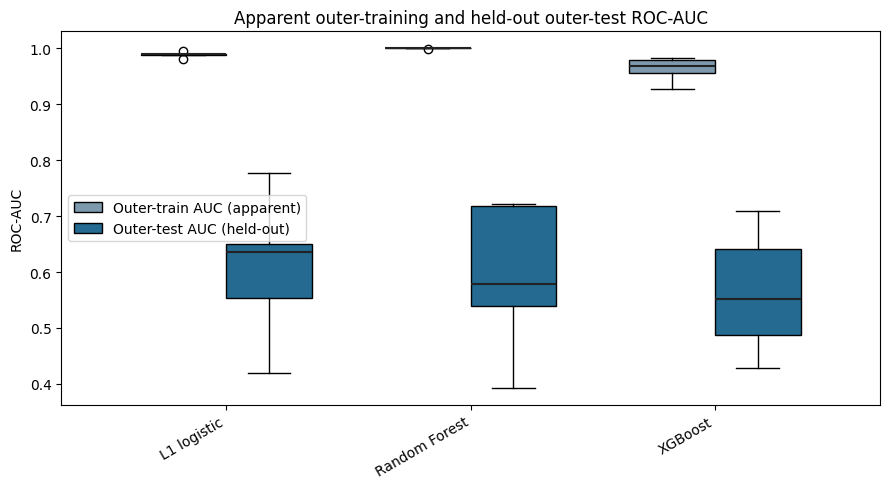

In [11]:
plot_train_test_boxplots_mutation(results_train_df, results_test_df, metric="roc_auc");

## Inspect L1 Logistic Regression Regularization and Sparsity

To better understand the behaviour of the L1-regularized logistic regression model, we inspect the hyperparameters selected during nested cross-validation.

`C` is the inverse of regularisation strength: larger values mean weaker regularisation.

For the L1-regularized model, we also inspect the number of non-zero coefficients across outer folds, because L1 regularization can shrink coefficients exactly to zero and therefore produce a sparse set of selected mutation features.

In [12]:
## Inspect Selected Logistic Regression Hyperparameters ##

selected_hyperparams_df = extract_selected_hyperparameters(results_test_df)

logreg_hyperparams_df = selected_hyperparams_df[
    selected_hyperparams_df["model"] == "logreg_l1"
].copy()

thesis_print("Selected L1 logistic regression hyperparameters across outer folds:")

thesis_display(
    logreg_hyperparams_df[
        [
            "model",
            "outer_fold",
            "roc_auc",
            "balanced_accuracy",
            "f1_macro",
            "selected_C",
            "selected_class_weight",
            "best_params"
        ]
    ].sort_values(["model", "outer_fold"])
)

thesis_print("Selected C values for L1 logistic regression:")
thesis_display(
    logreg_hyperparams_df
    .groupby(["model", "selected_C"])
    .size()
    .reset_index(name="n_outer_folds")
    .sort_values(["model", "selected_C"])
)

selected_hyperparams_df.to_csv(
    os.path.join(output_dir, "mutation_selected_hyperparameters_by_outer_fold_reviewed.csv"),
    index=False
)

logreg_hyperparams_df.to_csv(
    os.path.join(output_dir, "mutation_logreg_selected_hyperparameters_reviewed.csv"),
    index=False
)

Selected L1 logistic regression hyperparameters across outer folds:


,model,outer_fold,roc_auc,balanced_accuracy,f1_macro,selected_C,selected_class_weight,best_params
0,logreg_l1,1,0.778,0.690,0.686,0.1,None,"{""clf__C"": 0.1, ""clf__class_weight"": null, ""sa..."
1,logreg_l1,2,0.635,0.492,0.477,0.1,balanced,"{""clf__C"": 0.1, ""clf__class_weight"": ""balanced..."
2,logreg_l1,3,0.650,0.585,0.583,0.1,None,"{""clf__C"": 0.1, ""clf__class_weight"": null, ""sa..."
3,logreg_l1,4,0.419,0.423,0.333,0.1,balanced,"{""clf__C"": 0.1, ""clf__class_weight"": ""balanced..."
4,logreg_l1,5,0.554,0.366,0.358,0.1,balanced,"{""clf__C"": 0.1, ""clf__class_weight"": ""balanced..."


Selected C values for L1 logistic regression:


,model,selected_C,n_outer_folds
0,logreg_l1,0.1,5


In [13]:
## Inspect L1 Logistic Regression Sparsity ##

coefficient_threshold = 1e-8

logreg_l1_feature_rankings_df = feature_rankings_df[
    feature_rankings_df["model"] == "logreg_l1"
].copy()

logreg_l1_nonzero_df = (
    logreg_l1_feature_rankings_df
    .groupby("outer_fold")
    .agg(
        n_nonzero_coefficients=("selected_in_fold", "sum"),
        n_total_features=("gene", "nunique")
    )
    .reset_index()
)

logreg_l1_nonzero_df["fraction_nonzero"] = (
    logreg_l1_nonzero_df["n_nonzero_coefficients"]
    / logreg_l1_nonzero_df["n_total_features"]
)

logreg_l1_metrics_df = results_test_df[
    results_test_df["model"] == "logreg_l1"
][
    [
        "outer_fold",
        "roc_auc",
        "balanced_accuracy",
        "f1_macro",
        "best_params"
    ]
].copy()

logreg_l1_metrics_df["best_params_dict"] = (
    logreg_l1_metrics_df["best_params"].apply(parse_best_params_mutation)
)

logreg_l1_metrics_df["selected_C"] = (
    logreg_l1_metrics_df["best_params_dict"].apply(lambda x: x.get("clf__C"))
)

logreg_l1_metrics_df["selected_class_weight"] = (
    logreg_l1_metrics_df["best_params_dict"].apply(
        lambda x: x.get("clf__class_weight")
    )
)

logreg_l1_nonzero_df = logreg_l1_nonzero_df.merge(
    logreg_l1_metrics_df[
        [
            "outer_fold",
            "selected_C",
            "selected_class_weight",
            "roc_auc",
            "balanced_accuracy",
            "f1_macro"
        ]
    ],
    on="outer_fold",
    how="left"
)

thesis_print("Number of non-zero coefficients selected by logreg_l1 across outer folds:")
thesis_display(logreg_l1_nonzero_df)

logreg_l1_nonzero_df.to_csv(
    os.path.join(output_dir, "mutation_logreg_l1_nonzero_coefficients_by_outer_fold_reviewed.csv"),
    index=False
)

Number of non-zero coefficients selected by logreg_l1 across outer folds:


,outer_fold,n_nonzero_coefficients,n_total_features,fraction_nonzero,selected_C,selected_class_weight,roc_auc,balanced_accuracy,f1_macro
0,1,42,4552,0.009,0.1,None,0.778,0.690,0.686
1,2,28,4552,0.006,0.1,balanced,0.635,0.492,0.477
2,3,27,500,0.054,0.1,None,0.650,0.585,0.583
3,4,21,500,0.042,0.1,balanced,0.419,0.423,0.333
4,5,26,4552,0.006,0.1,balanced,0.554,0.366,0.358


### ROC curve — Full availability (N=112)

We plot ROC curves across outer folds for each model using the saved fold-level predictions.

--- Plotting ROC Curve ---


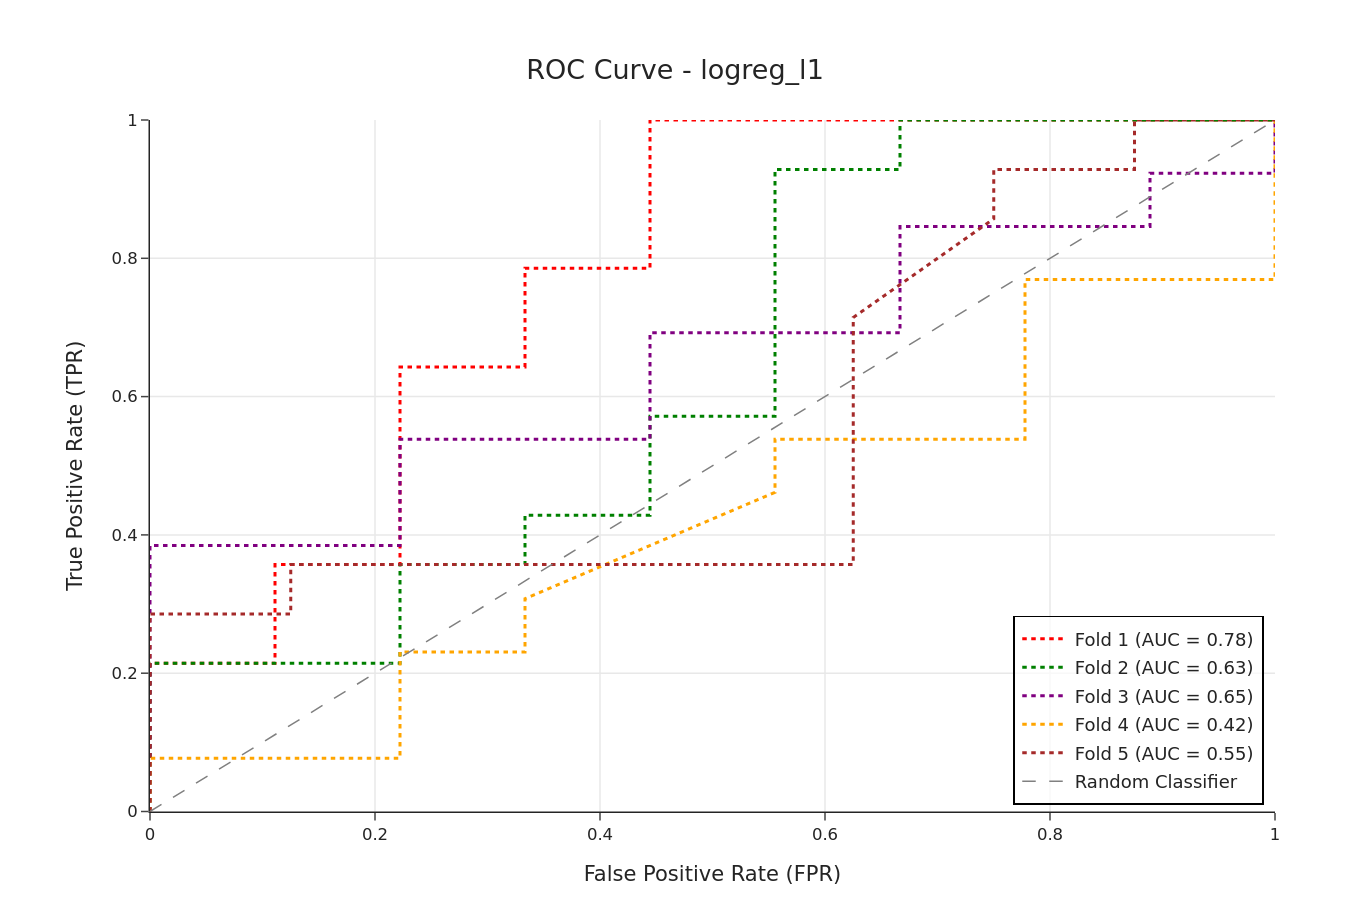

--- Plotting ROC Curve ---


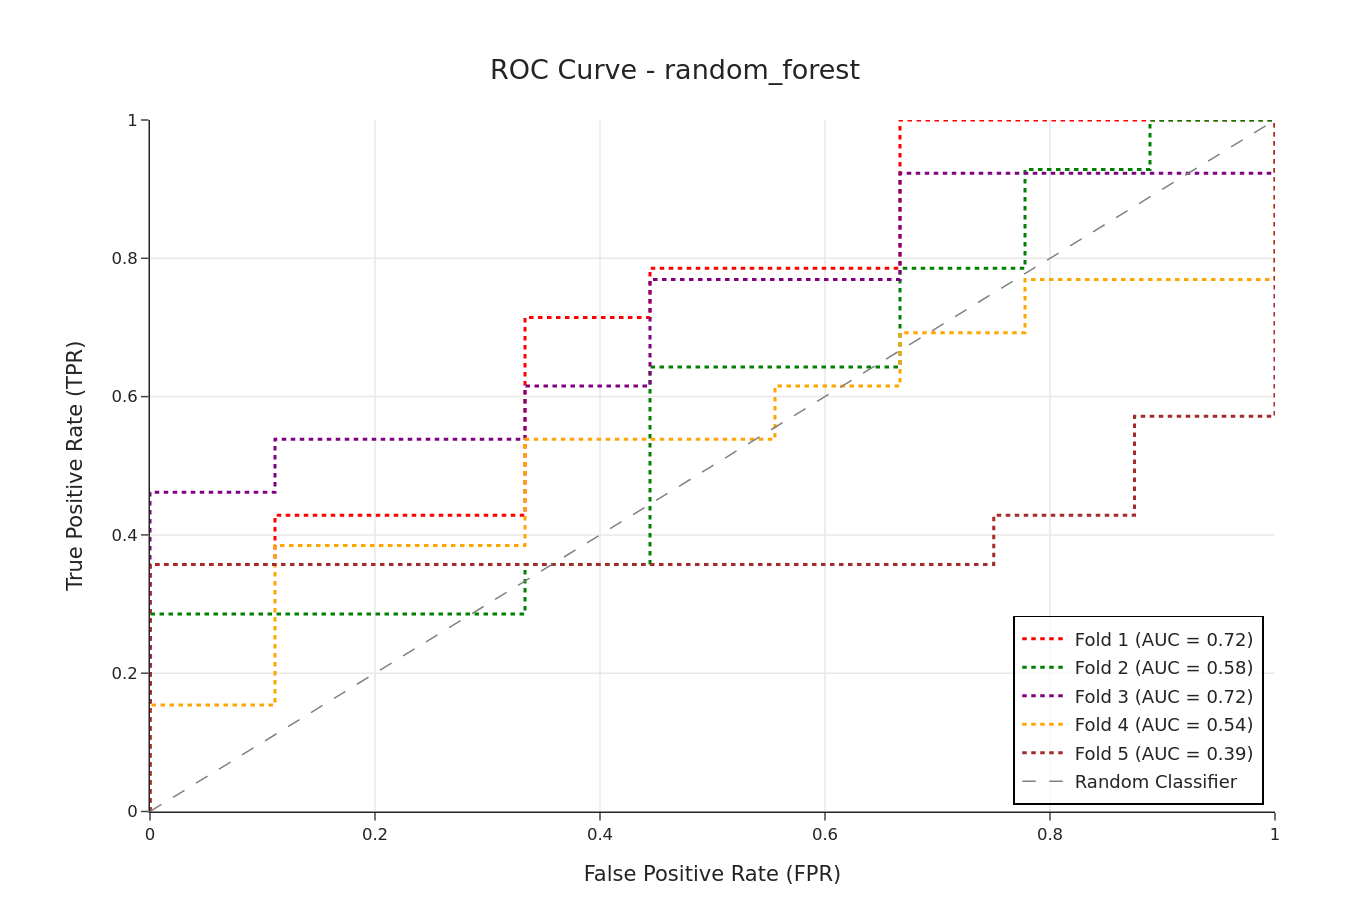

--- Plotting ROC Curve ---


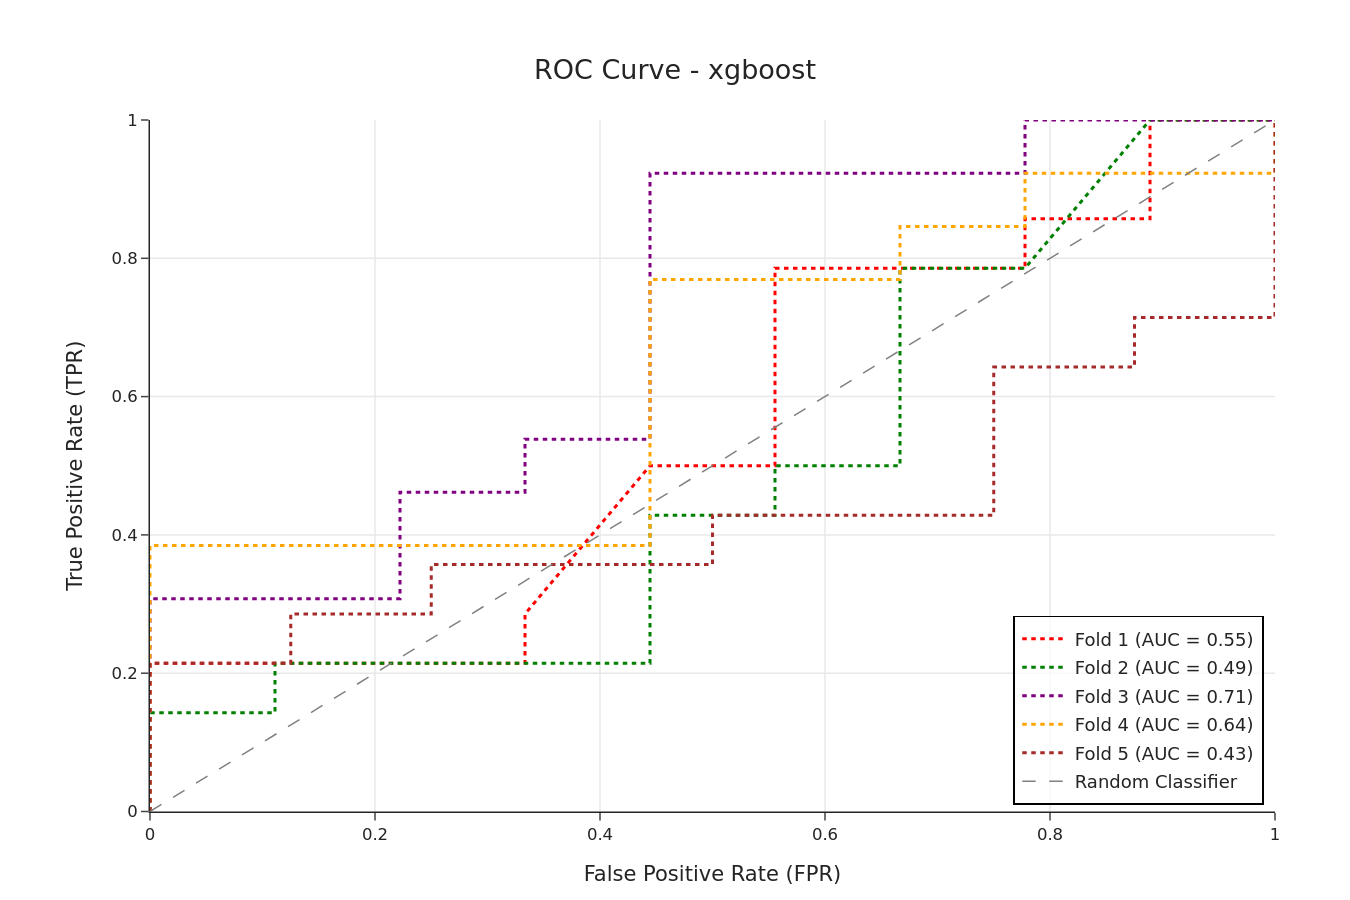

In [14]:
for model_name in predictions_df["model"].unique():

    model_predictions_df = predictions_df[
        predictions_df["model"] == model_name
    ].copy()

    curves_data = []

    for fold_idx in sorted(
        model_predictions_df["outer_fold"].unique()
    ):

        fold_predictions_df = model_predictions_df[
            model_predictions_df["outer_fold"] == fold_idx
        ]

        curves_data.append({
            "y_true": fold_predictions_df["y_true"].values,
            "y_prob": fold_predictions_df["y_proba"].values,
            "label": f"Fold {fold_idx}",
            "is_main_curve": False
        })

    plot_roc_curves(
        curves_data=curves_data,
        title=f"ROC Curve - {model_name}",
        interactive=False
    )

### ROC curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

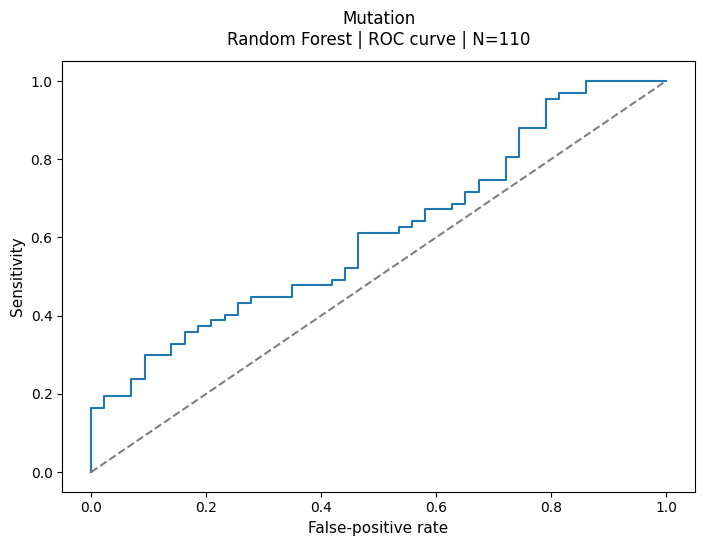

In [2]:
fig = plot_thesis_saved_figure('roc', 'mutation')
plt.show()


### Precision–Recall curve — Full availability (N=112)

Because the dataset is imbalanced, precision-recall curves are reported. The curves are computed separately for each outer fold using held-out predictions only.

--- Plotting Precision–Recall Curve ---


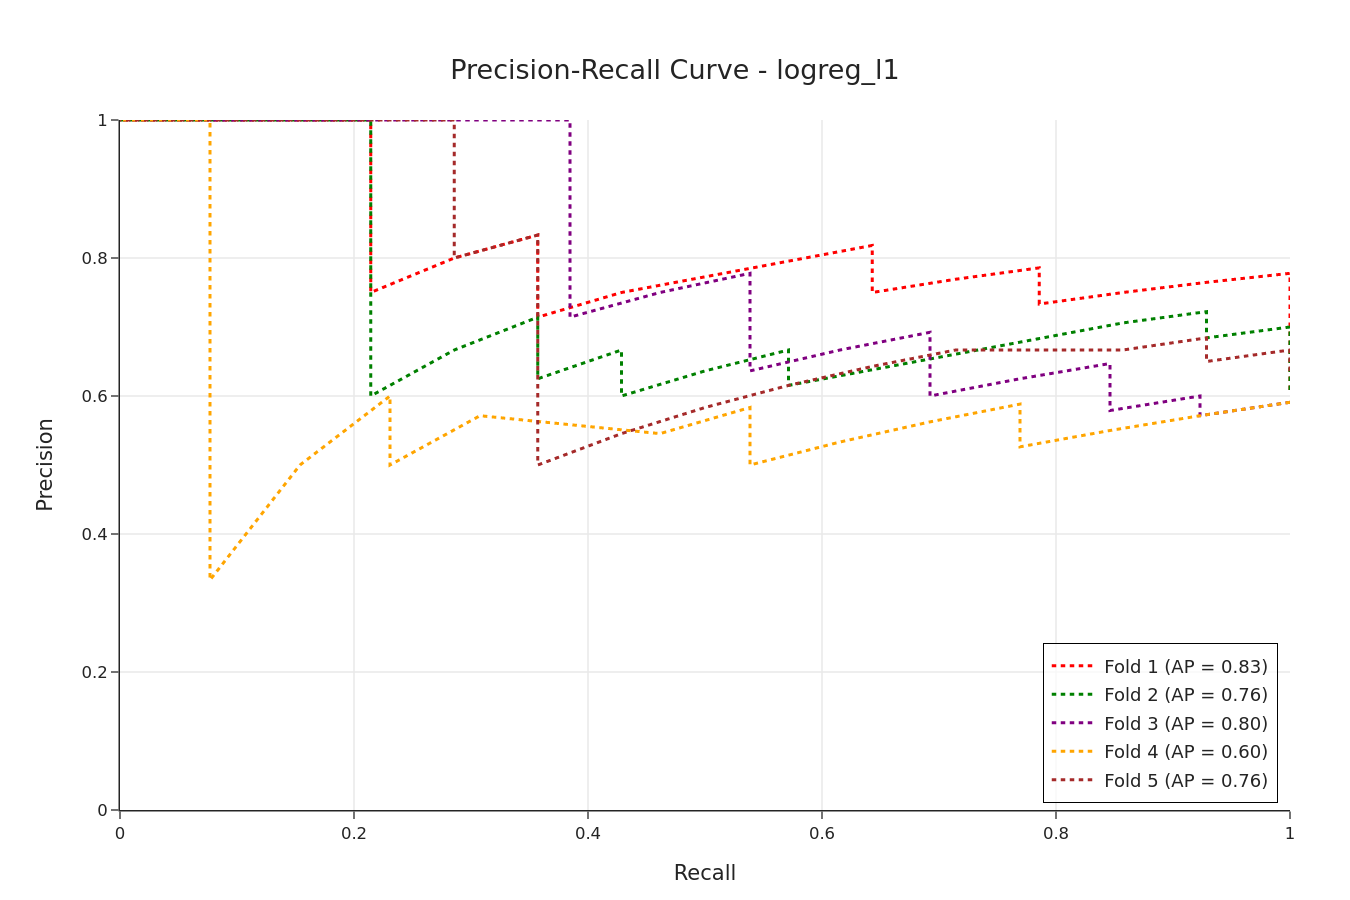

--- Plotting Precision–Recall Curve ---


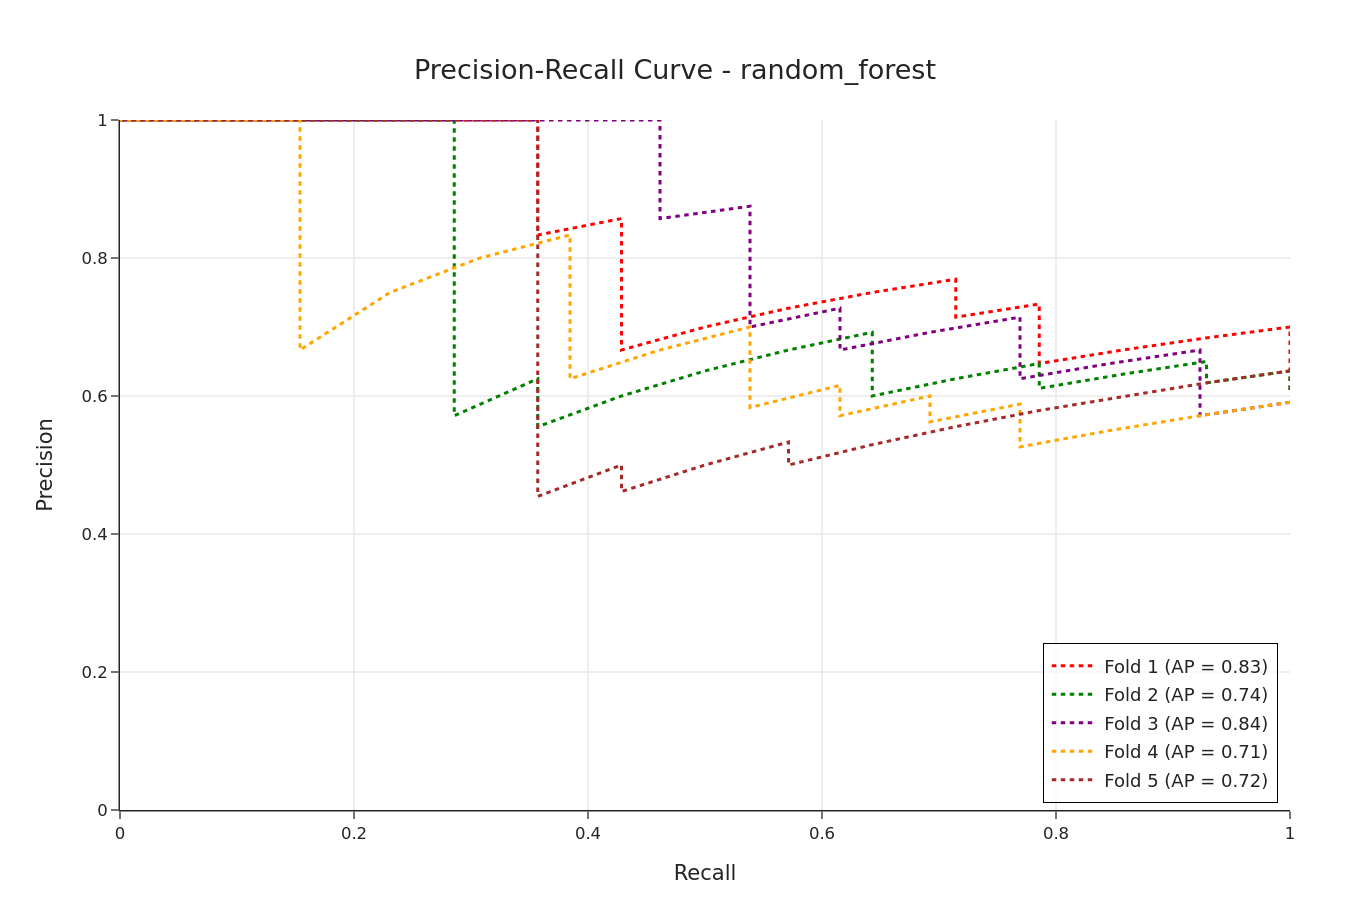

--- Plotting Precision–Recall Curve ---


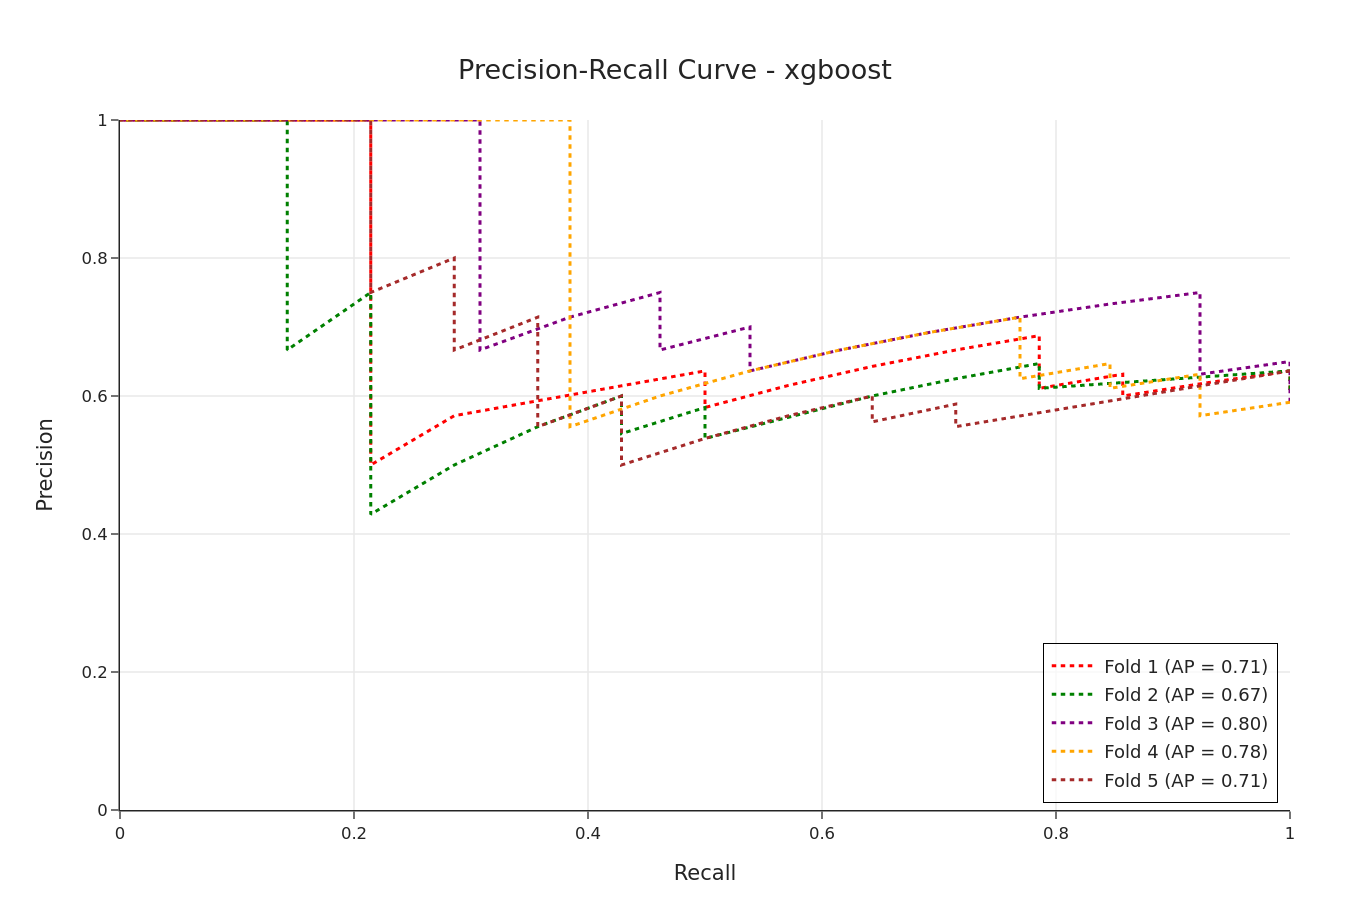

In [15]:
## Plot Precision-Recall Curves ##

for model_name in predictions_df["model"].unique():

    model_predictions_df = predictions_df[
        predictions_df["model"] == model_name
    ].copy()

    curves_data = []

    for fold_idx in sorted(
        model_predictions_df["outer_fold"].unique()
    ):

        fold_predictions_df = model_predictions_df[
            model_predictions_df["outer_fold"] == fold_idx
        ]

        curves_data.append({
            "y_true": fold_predictions_df["y_true"].values,
            "y_prob": fold_predictions_df["y_proba"].values,
            "label": f"Fold {fold_idx}",
            "is_main_curve": False
        })

    plot_precision_recall_curves(
        curves_data=curves_data,
        title=f"Precision-Recall Curve - {model_name}",
        interactive=False
    )

### Precision–Recall curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

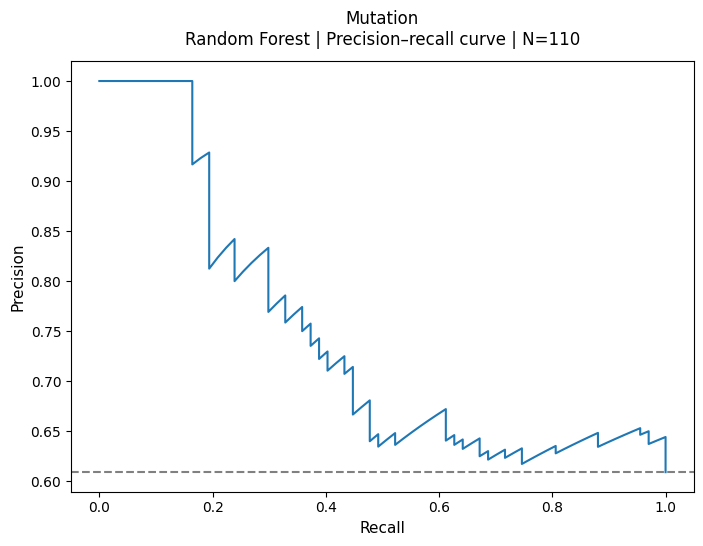

In [3]:
fig = plot_thesis_saved_figure('pr', 'mutation')
plt.show()


### Confusion matrix — Full availability (N=112)

We compute aggregated confusion matrices for each model using the saved fold-level predictions.

--- Plotting Confusion Matrix ---


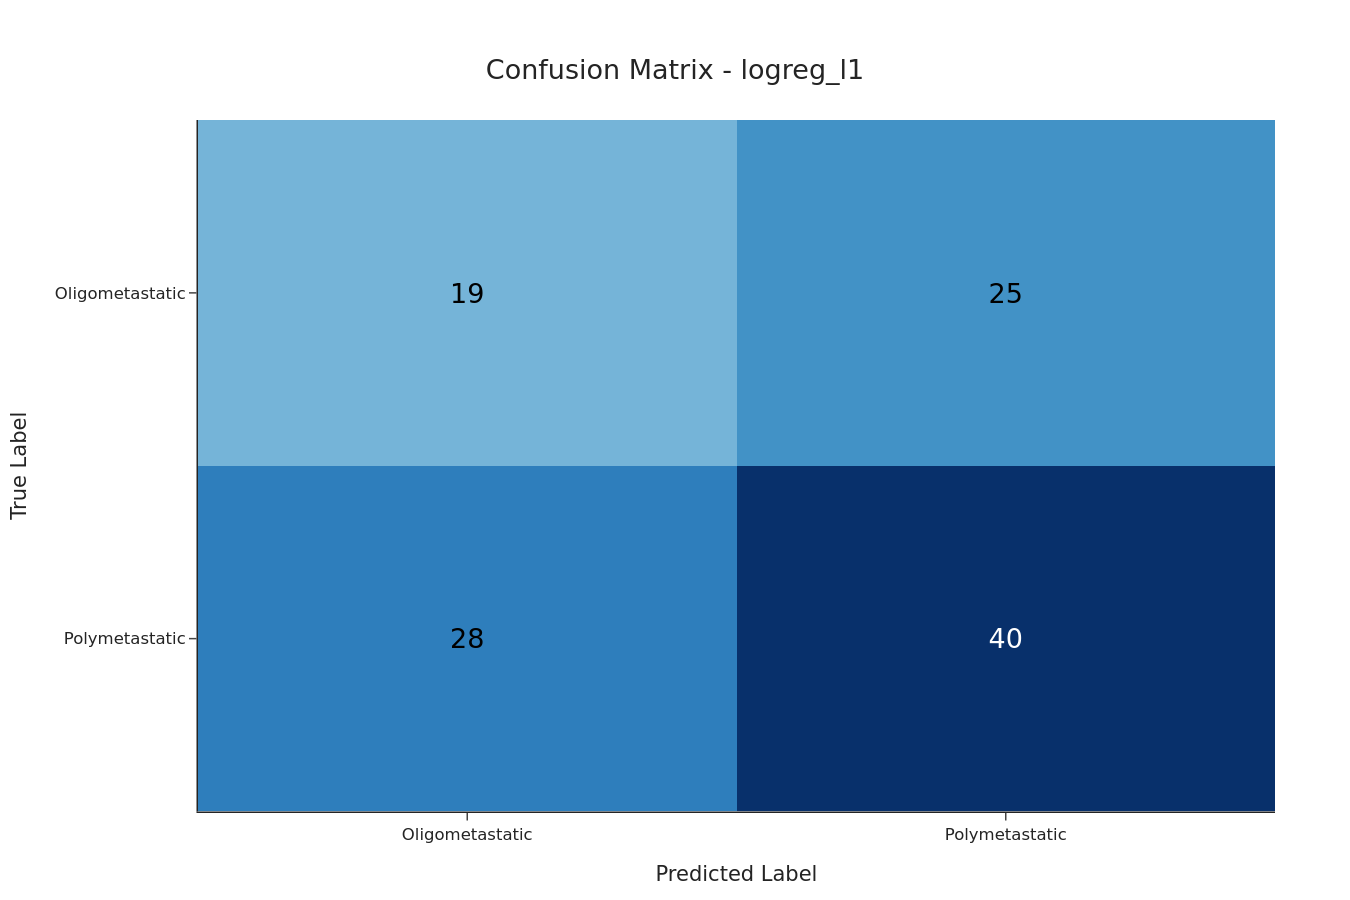

--- Plotting Confusion Matrix ---


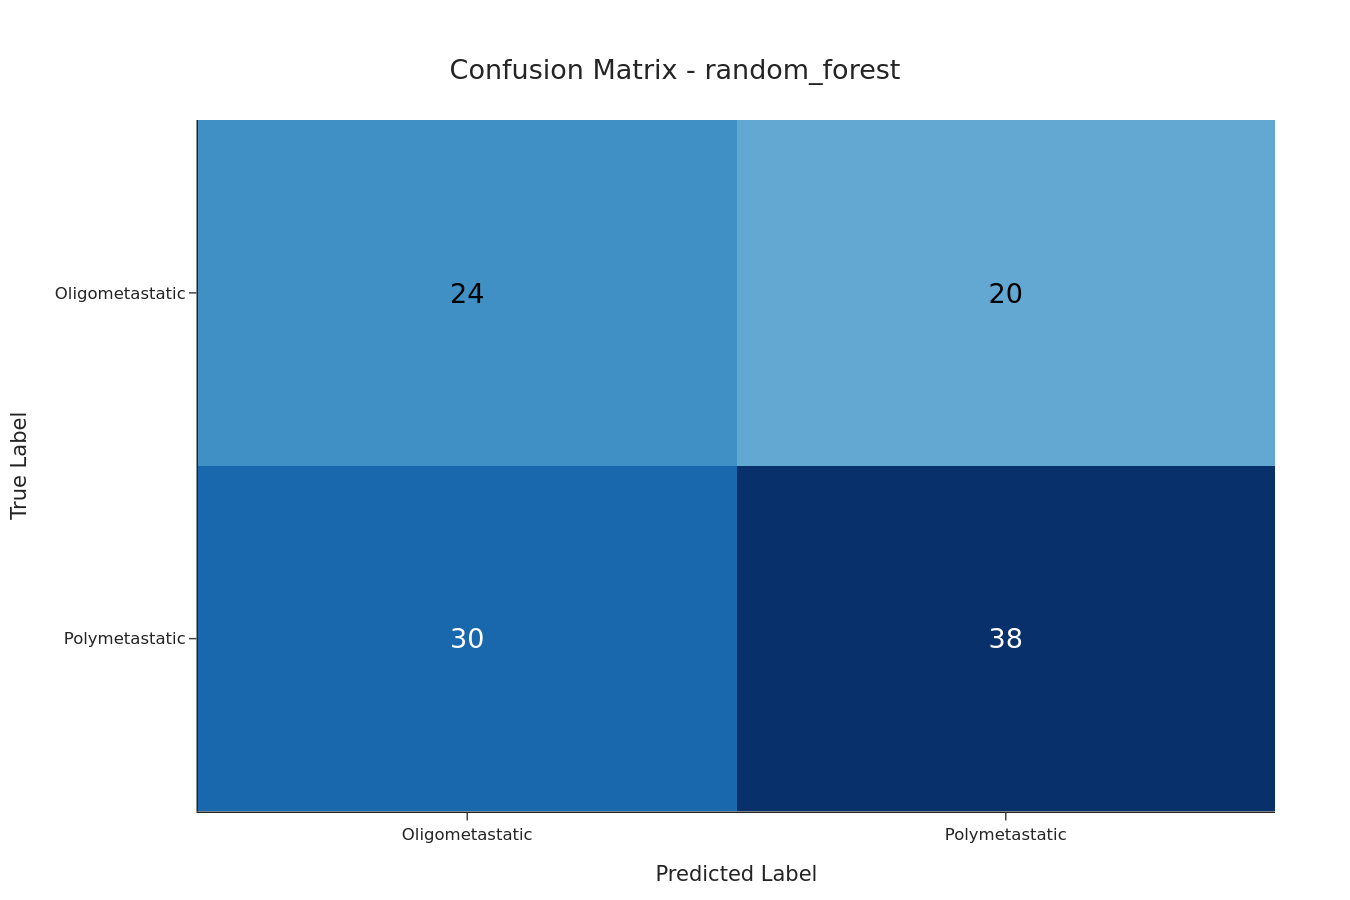

--- Plotting Confusion Matrix ---


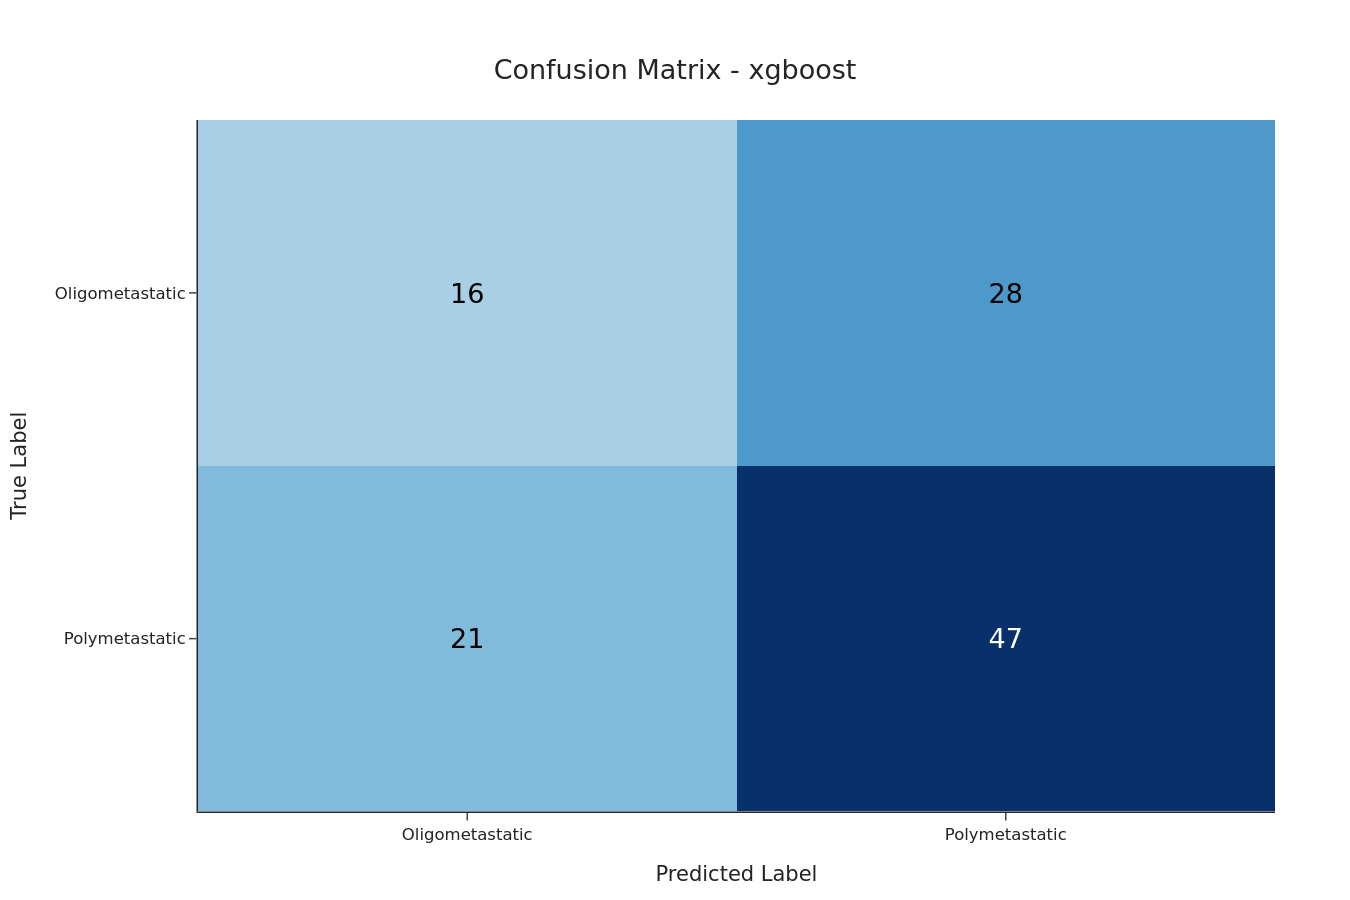

In [16]:
for model_name in predictions_df["model"].unique():

    model_predictions_df = predictions_df[
        predictions_df["model"] == model_name
    ]

    plot_confusion_matrix(
        y_true=model_predictions_df["y_true"],
        y_pred=model_predictions_df["y_pred"],
        class_labels=["Oligometastatic", "Polymetastatic"],
        title=f"Confusion Matrix - {model_name}",
        interactive=False
    )

### Confusion matrix — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

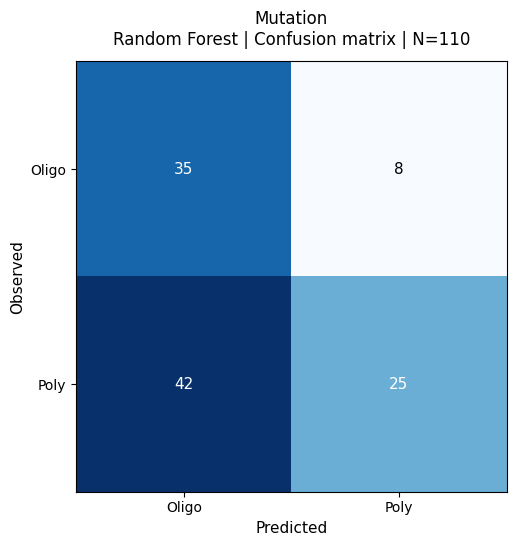

In [4]:
fig = plot_thesis_saved_figure('confusion_matrix', 'mutation')
plt.show()


## Select the Predictive Model

Candidate predictive models are compared according to the mean inner-cross-validation score across outer folds.

Outer-fold test metrics are displayed only to estimate out-of-training performance and are not used for model selection.

The selected predictive model will also be used for gene-level interpretation. This avoids selecting one model for prediction and then interpreting features from a different model family.

In [17]:
metrics = [
    "roc_auc",
    "balanced_accuracy",
    "f1",
    "f1_macro",
    "f1_weighted",
    "precision",
    "recall"
]

model_selection_summary = (
    results_test_df
    .groupby("model")
    .agg(
        mean_inner_cv_score=("best_inner_score", "mean"),
        std_inner_cv_score=("best_inner_score", "std"),
        mean_test_roc_auc=("roc_auc", "mean"),
        mean_test_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_test_f1=("f1", "mean"),
        mean_test_f1_macro=("f1_macro", "mean"),
        mean_test_f1_weighted=("f1_weighted", "mean"),
        mean_test_precision=("precision", "mean"),
        mean_test_recall=("recall", "mean")
    )
    .sort_values(by="mean_inner_cv_score", ascending=False)
)

model_selection_summary = model_selection_summary.sort_index().sort_values(
    "mean_inner_cv_score", ascending=False, kind="stable"
)
for metric in metrics:
    model_selection_summary[f"std_test_{metric}"] = results_test_df.groupby("model")[metric].std()

thesis_print("Model selection summary (outer-fold means and sample SD):")
thesis_display(model_selection_summary)

selected_predictive_model = model_selection_summary.index[0]

# The selected predictive model is also used for gene-level interpretation.
interpretable_model = selected_predictive_model

thesis_print(
    "Selected predictive model based on mean inner-cross-validation score:",
    selected_predictive_model
)

thesis_print(
    "Outer-fold test metrics are reported only for out-of-training "
    "performance estimation, not for model selection."
)

thesis_print("Model used for gene-level interpretation:", interpretable_model)

model_selection_summary.to_csv(
    os.path.join(output_dir, "mutation_model_selection_summary_reviewed.csv")
)

Model selection summary (outer-fold means and sample SD):


,mean_inner_cv_score,std_inner_cv_score,mean_test_roc_auc,mean_test_balanced_accuracy,mean_test_f1,mean_test_f1_macro,mean_test_f1_weighted,mean_test_precision,mean_test_recall,std_test_roc_auc,std_test_balanced_accuracy,std_test_f1,std_test_f1_macro,std_test_f1_weighted,std_test_precision,std_test_recall
model,,,,,,,,,,,,,,,,
random_forest,0.663,0.030,0.590,0.552,0.601,0.539,0.552,0.670,0.559,0.137,0.125,0.101,0.118,0.112,0.138,0.121
xgboost,0.661,0.030,0.564,0.531,0.624,0.504,0.529,0.598,0.698,0.113,0.145,0.232,0.157,0.165,0.120,0.353
logreg_l1,0.603,0.049,0.607,0.511,0.593,0.488,0.508,0.617,0.592,0.132,0.129,0.132,0.149,0.137,0.105,0.201


Selected predictive model based on mean inner-cross-validation score: random_forest
Outer-fold test metrics are reported only for out-of-training performance estimation, not for model selection.
Model used for gene-level interpretation: random_forest


### Inner-score family stability and selected-family OOF evaluation

Fold ranks and winner counts use only best_inner_score; alphabetical order breaks exact ties. These are stability diagnostics, not a mixed-family common-cohort estimator. Global family selection remains based on mean inner-CV macro-F1, never outer-test metrics. The selected family's pooled OOF result is not an independent validation of the global family-selection step.

Random Forest remains the globally selected family, with mean inner-CV macro-F1 of 0.6627, compared with 0.6606 for XGBoost and 0.6025 for L1 logistic regression. XGBoost wins four outer folds, Random Forest one and L1 none. Fold wins ignore the magnitude of score differences and therefore need not agree with the predefined mean-score criterion.


,outer_fold,model,best_inner_score,rank,is_winner
0,1,xgboost,0.702,1,True
1,1,random_forest,0.691,2,False
2,1,logreg_l1,0.642,3,False
3,2,xgboost,0.681,1,True
4,2,random_forest,0.665,2,False
5,2,logreg_l1,0.578,3,False
6,3,xgboost,0.633,1,True
7,3,random_forest,0.624,2,False
8,3,logreg_l1,0.532,3,False
9,4,xgboost,0.649,1,True


,outer_fold_wins
model,
logreg_l1,0
random_forest,1
xgboost,4


,model,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score,n_subjects
1,random_forest,0.572,0.552,0.546,0.655,0.559,0.545,0.729,0.245,112


--- Plotting ROC Curve ---


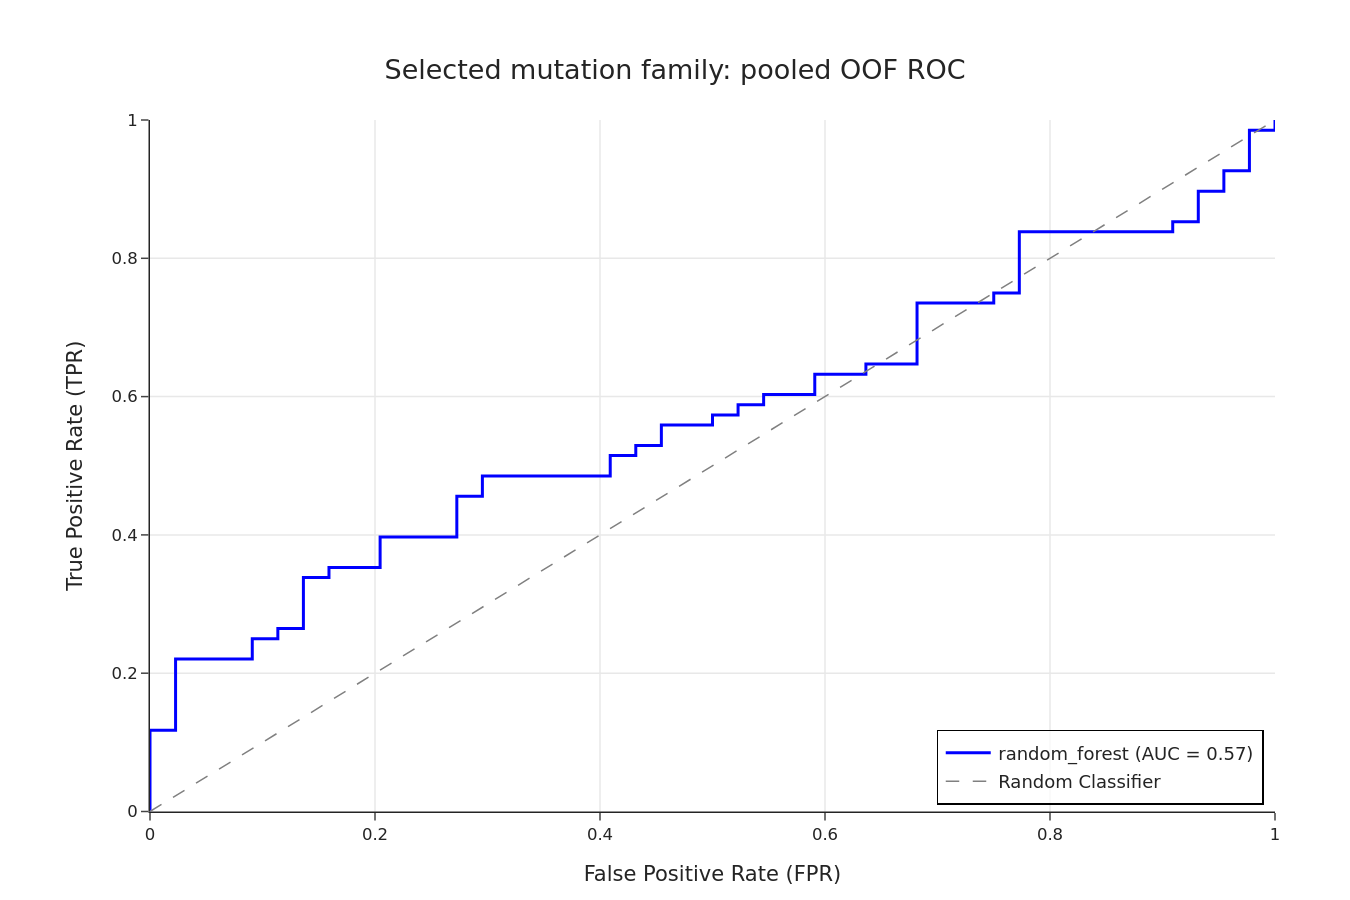

--- Plotting Precision–Recall Curve ---


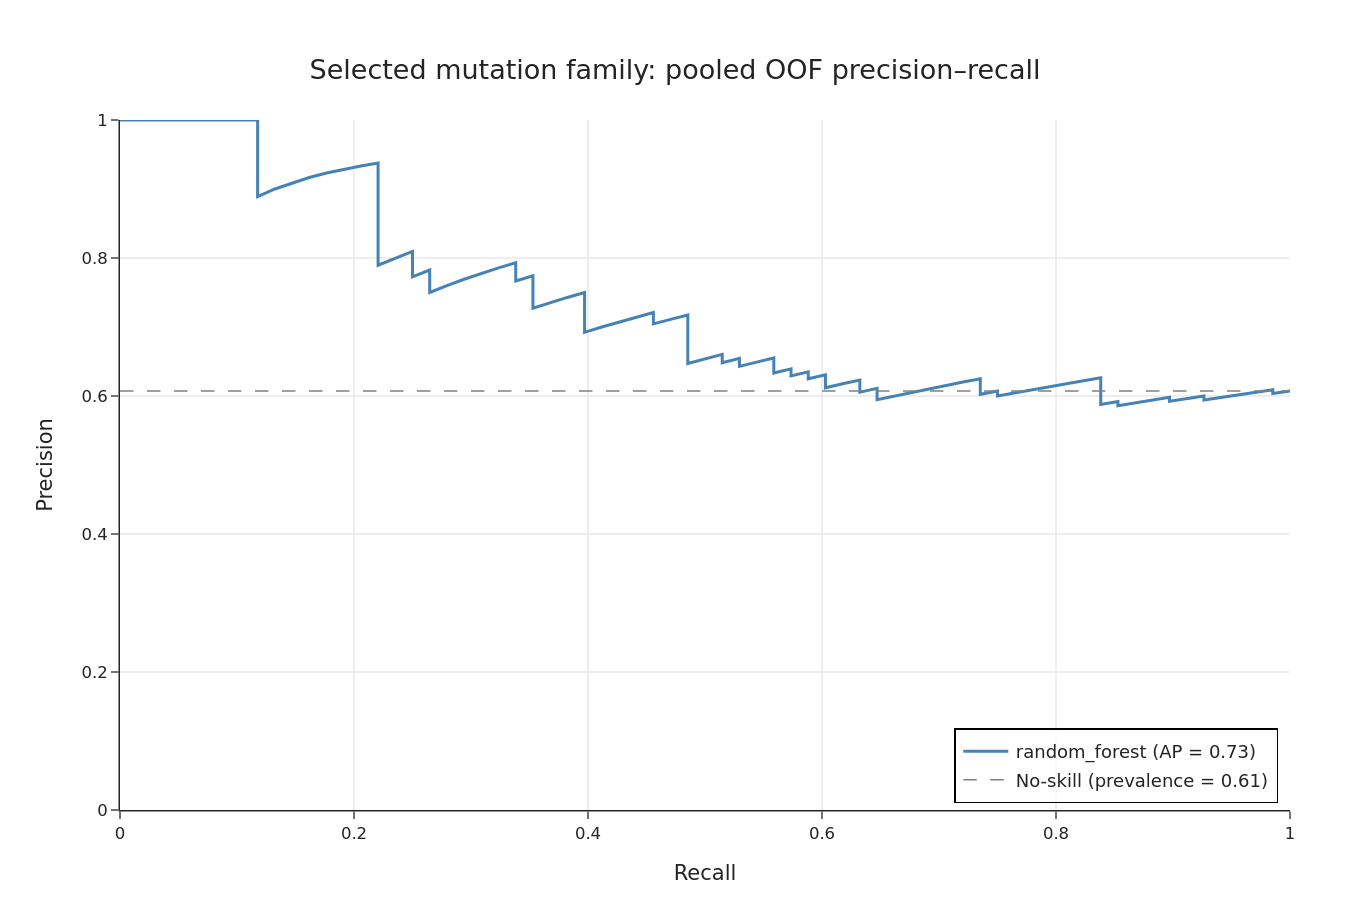

--- Plotting Confusion Matrix ---


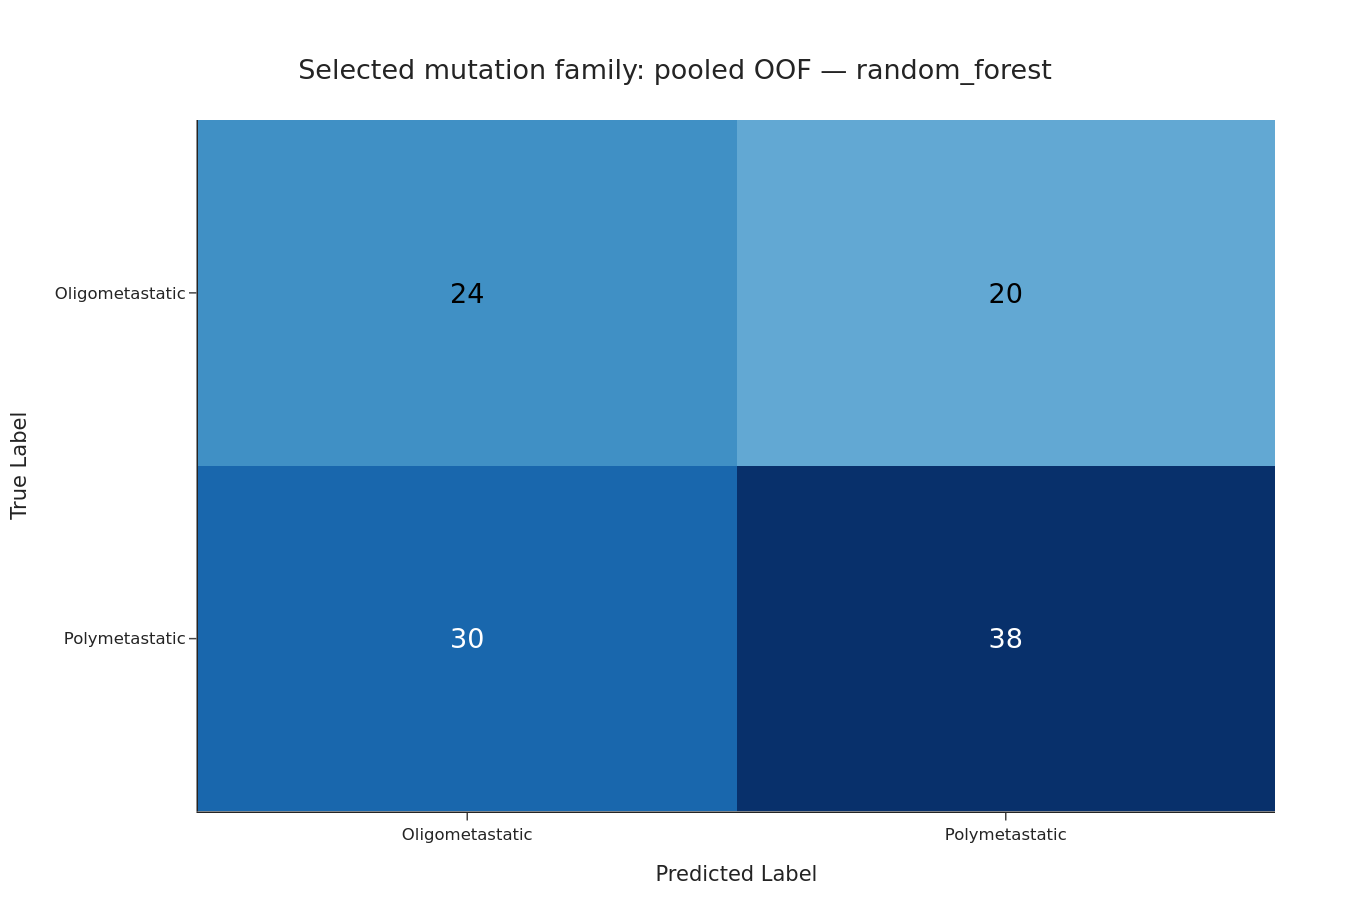

In [18]:
inner_fold_ranking_df, model_fold_wins_df = rank_mutation_inner_scores(
    results_test_df, list(models), n_outer_folds=len(outer_splits)
)
thesis_display(inner_fold_ranking_df)
thesis_display(model_fold_wins_df)
inner_fold_ranking_df.to_csv(Path(output_dir) / "mutation_inner_fold_ranking_reviewed.csv", index=False)
model_fold_wins_df.to_csv(Path(output_dir) / "mutation_model_fold_wins_reviewed.csv")
selected_oof_df = validated_oof_by_model[selected_predictive_model]
selected_pooled_oof_df = pooled_oof_metrics_df.loc[pooled_oof_metrics_df.model == selected_predictive_model].copy()
thesis_display(selected_pooled_oof_df)
selected_pooled_oof_df.to_csv(Path(output_dir) / "mutation_selected_pooled_oof_metrics_reviewed.csv", index=False)
selected_curve = [{"y_true": selected_oof_df.y_true, "y_prob": selected_oof_df.y_proba,
                   "label": selected_predictive_model, "is_main_curve": True}]
plot_roc_curves(selected_curve, title="Selected mutation family: pooled OOF ROC", interactive=False)
plot_precision_recall_curves(selected_curve, title="Selected mutation family: pooled OOF precision–recall", interactive=False)
plot_confusion_matrix(selected_oof_df.y_true, selected_oof_df.y_pred,
    class_labels=["Oligometastatic", "Polymetastatic"],
    title=f"Selected mutation family: pooled OOF — {selected_predictive_model}", interactive=False)


### Family selection in both contexts

The selected family in each column is determined by the highest mean inner-CV macro-F1. Values summarise five outer folds. The common-cohort (N=110) protocol uses compact common-cohort grids, inner/outer training-local preprocessing, seeded MI, no resampling and fit-local XGBoost weighting.

In [5]:
p110_selection_file = p110_prefix + ('_representation' if p110_config == 'transcriptomics' else '') + '_model_selection_summary_reviewed.csv'
p110_secondary_selection = p110_pd.read_csv(p110_root.parent / p110_folder / p110_selection_file)
p110_key = 'representation' if p110_config == 'transcriptomics' else 'model'
if p110_config == 'transcriptomics':
    p110_secondary_selection = p110_secondary_selection[p110_secondary_selection.representation.str.startswith('gene_level_')].copy()
p110_secondary_selection['family'] = p110_secondary_selection[p110_key].str.replace('gene_level_', '', regex=False)
p110_primary_selection = p110_bundle['ranking'].query('configuration == @p110_config').copy()
p110_selection_comparison = p110_secondary_selection[['family','mean_inner_cv_score','std_inner_cv_score']].merge(
    p110_primary_selection[['family','mean_inner_macro_f1','std_inner_macro_f1']],on='family',how='outer',validate='one_to_one')
p110_selection_comparison['Selected — '+p110_secondary_label] = p110_selection_comparison.family.eq(p110_secondary_family.removeprefix('gene_level_'))
p110_selection_comparison['Selected — '+p110_primary_label] = p110_selection_comparison.family.eq(p110_primary_family)
p110_selection_comparison = p110_selection_comparison.rename(columns={
    'mean_inner_cv_score':p110_secondary_label+' mean inner macro-F1',
    'std_inner_cv_score':p110_secondary_label+' SD',
    'mean_inner_macro_f1':p110_primary_label+' mean inner macro-F1',
    'std_inner_macro_f1':p110_primary_label+' SD'})
thesis_display(p110_selection_comparison.fillna('—'))

,family,Full availability (N=112) mean inner macro-F1,Full availability (N=112) SD,Common cohort (N=110) mean inner macro-F1,Common cohort (N=110) SD,Selected — Full availability (N=112),Selected — Common cohort (N=110)
0,logreg_l1,0.603,0.049,0.566,0.039,False,False
1,random_forest,0.663,0.030,0.581,0.020,True,True
2,xgboost,0.661,0.030,0.490,0.041,False,False


## Sampler Selection Diagnostic

Because SMOTE is treated as a hyperparameter rather than applied by default, we inspect which resampling strategy was selected by the inner cross-validation loop in each outer fold and for each model family.

This shows which configurations used synthetic oversampling. Other hyperparameters varied at the same time, so it cannot show a causal effect of SMOTE.

In [19]:
sampler_choice_df = results_test_df[["model", "outer_fold", "best_params"]].copy()

sampler_choice_df["best_params_parsed"] = sampler_choice_df["best_params"].apply(json.loads)

sampler_choice_df["sampler_chosen"] = sampler_choice_df["best_params_parsed"].apply(
    lambda d: d.get("sampler", "passthrough")
)

thesis_print("Sampler chosen per outer fold, per model:")

thesis_display(
    sampler_choice_df[
        ["model", "outer_fold", "sampler_chosen"]
    ]
)

thesis_print("\nSampler choice frequency, per model:")

thesis_display(
    sampler_choice_df
    .groupby(["model", "sampler_chosen"])
    .size()
    .unstack(fill_value=0)
)

Sampler chosen per outer fold, per model:


,model,outer_fold,sampler_chosen
0,logreg_l1,1,SMOTE(random_state=42)
1,logreg_l1,2,passthrough
2,logreg_l1,3,SMOTE(random_state=42)
3,logreg_l1,4,passthrough
4,logreg_l1,5,passthrough
5,random_forest,1,passthrough
6,random_forest,2,passthrough
7,random_forest,3,passthrough
8,random_forest,4,passthrough
9,random_forest,5,passthrough



Sampler choice frequency, per model:


sampler_chosen,SMOTE(random_state=42),passthrough
model,,
logreg_l1,2,3
random_forest,0,5
xgboost,2,3


## Feature-Selector Selection Diagnostic

Feature selection is also treated as a hyperparameter. We therefore inspect which selector configuration was selected by the inner cross-validation loop for each model and outer fold.

This shows whether the model preferred no explicit pre-selection, ANOVA-based SelectKBest, or mutual-information-based SelectKBest.

In [20]:
selector_choice_df = results_test_df[["model", "outer_fold", "best_params"]].copy()

selector_choice_df["best_params_parsed"] = selector_choice_df["best_params"].apply(json.loads)

selector_choice_df["selector_chosen"] = selector_choice_df["best_params_parsed"].apply(
    lambda d: d.get("selector", "passthrough")
)

thesis_print("Feature selector chosen per outer fold, per model:")

thesis_display(
    selector_choice_df[
        ["model", "outer_fold", "selector_chosen"]
    ]
)

thesis_print("\nFeature selector choice frequency, per model:")

thesis_display(
    selector_choice_df
    .groupby(["model", "selector_chosen"])
    .size()
    .unstack(fill_value=0)
)

Feature selector chosen per outer fold, per model:


,model,outer_fold,selector_chosen
0,logreg_l1,1,passthrough
1,logreg_l1,2,passthrough
2,logreg_l1,3,SelectKBest(k=500)
3,logreg_l1,4,SelectKBest(k=500)
4,logreg_l1,5,passthrough
5,random_forest,1,SelectKBest(k=200)
6,random_forest,2,SelectKBest(k=200)
7,random_forest,3,SelectKBest(k=500)
8,random_forest,4,"SelectKBest(k=200, score_func=<function mutual..."
9,random_forest,5,SelectKBest(k=500)



Feature selector choice frequency, per model:


selector_chosen,SelectKBest(k=200),"SelectKBest(k=200, score_func=<function mutual_info_classif at 0x7423114b4cc0>)",SelectKBest(k=500),passthrough
model,,,,
logreg_l1,0,0,2,3
random_forest,2,1,2,0
xgboost,0,5,0,0


### Calibration curve — Full availability (N=112)


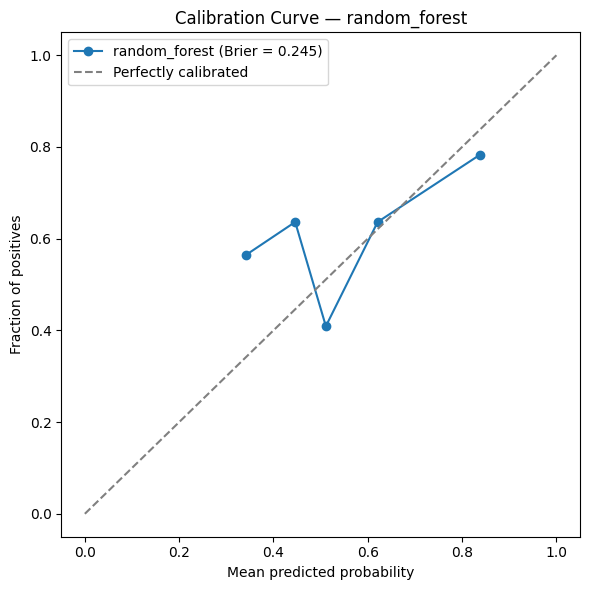

0.245

In [21]:
thesis_display(plot_calibration_curve(predictions_df, selected_predictive_model, n_bins=5))


### Calibration curve — Common cohort (N=110)

Selected-family pooled OOF predictions from the shared 110-patient comparison.

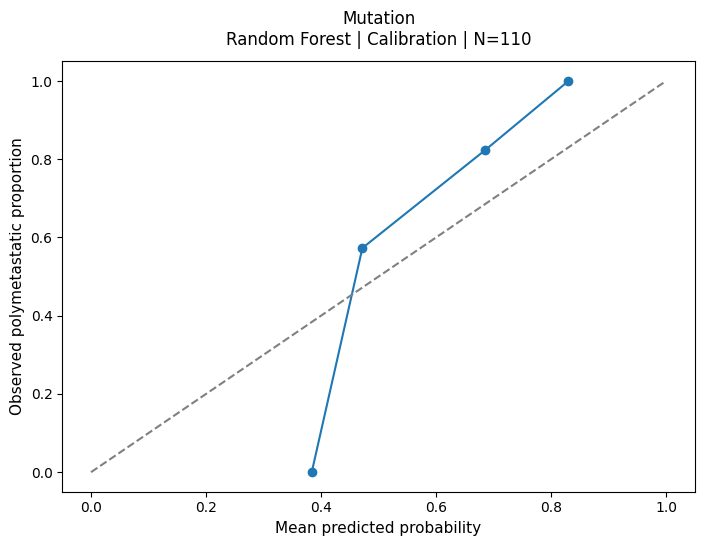

In [5]:
fig = plot_thesis_saved_figure('calibration', 'mutation')
plt.show()


### Calibration Interpretation — Full availability (N=112)

The selected Random Forest model has a pooled OOF Brier score of 0.2455. This measures overall probabilistic error and does not on its own show good calibration. Its pooled ROC-AUC of 0.5715 and balanced accuracy of 0.5521 indicate limited held-out discrimination.

The calibration plot provides a descriptive check of predicted probabilities against observed outcome frequencies. With only 112 subjects, bin-level estimates may be unstable. These results do not support treating the model's probabilities as reliable individual-level risk estimates without independent validation.


--- Plotting: Model Selection: Inner-CV Score vs. Test Metrics ---


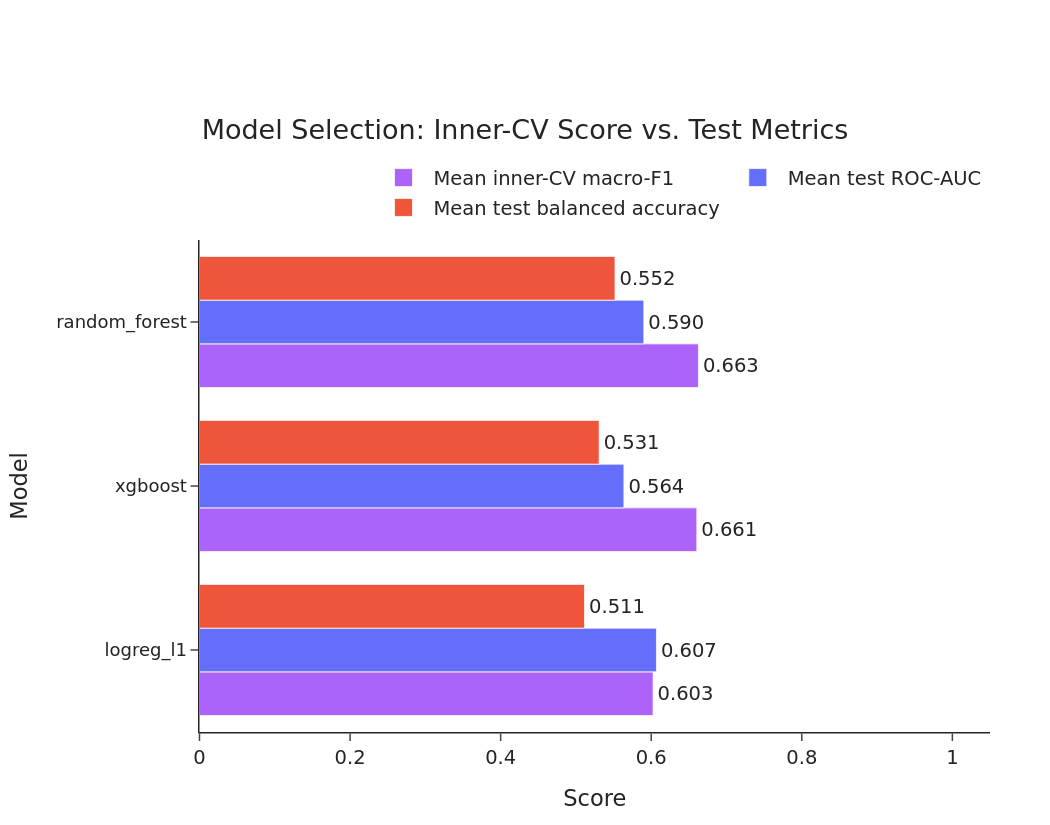

In [22]:
model_selection_plot_df = model_selection_summary.reset_index().rename(
    columns={"index": "model"}
)

plot_combined_ranking(
    model_selection_plot_df,
    sort_by="mean_inner_cv_score",
    metrics=[
        ("mean_inner_cv_score", "#AB63FA", "Mean inner-CV macro-F1"),
        ("mean_test_roc_auc", "#636EFA", "Mean test ROC-AUC"),
        ("mean_test_balanced_accuracy", "#EF553B", "Mean test balanced accuracy"),
    ],
    data_type_col="model",
    title="Model Selection: Inner-CV Score vs. Test Metrics",
    xaxis_title="Score",
    yaxis_title="Model",
    margin=dict(t=160, b=60, l=120, r=40),
    height=550,
    interactive=False
);

## Summary of predictive results

### Full availability (N=112)

Random Forest remains the globally selected family because it has the highest mean inner-CV macro-F1 (0.6627), narrowly ahead of XGBoost (0.6606) and L1 logistic regression (0.6025). XGBoost wins four outer folds and Random Forest one, but selection uses the mean score, not win counts.

### Held-out performance

Mean outer-fold ROC-AUC was 0.6069 for L1 logistic regression, 0.5902 for Random Forest and 0.5637 for XGBoost. Their pooled OOF ROC-AUC values were 0.6163, 0.5715 and 0.5384, respectively. Fold means and pooled metrics are different summaries; neither is used to change the selected family.

For Random Forest, pooled balanced accuracy was 0.5521, macro-F1 0.5465, precision 0.6552, sensitivity/recall 0.5588, specificity 0.5455, average precision 0.7294 and Brier score 0.2455. These results indicate limited discrimination. Train–test ROC-AUC gaps of approximately 0.410 for Random Forest, 0.399 for XGBoost and 0.382 for L1 highlight substantial overfitting and instability.

Global family selection lacks independent validation, and the documented upstream-filtering and complete-cohort class-ratio limitations remain.

### Common cohort (N=110)

Random Forest was selected by the highest mean inner-CV macro-F1 (0.581). Pooled OOF ROC-AUC was 0.611, balanced accuracy 0.594, macro-F1 0.542 and Brier score 0.233. This is the common-cohort result for cross-modality comparison on the same 110 patients and frozen outer folds. Performance remains exploratory and does not establish clinical utility. Differences between contexts involve preprocessing and search spaces as well as cohort membership; they cannot be attributed solely to sample size.

## Saved Modelling Results

The following result categories are saved as CSV files or displayed as figures.

* fold-level test results;
* fold-level train results;
* fold-level predictions;
* selected hyperparameters across outer folds;
* train-versus-test comparison;
* L1 logistic regression non-zero coefficient counts across outer folds;
* model selection summary based on mean inner-cross-validation score;
* ROC curves and confusion matrices.

In [37]:
thesis_print("Revised output inventory (written by the corresponding enabled stages):")
thesis_print(os.path.join(output_dir, "mutation_nested_cv_test_results_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_nested_cv_train_results_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_nested_cv_predictions_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_nested_cv_feature_rankings_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_selected_hyperparameters_by_outer_fold_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_logreg_selected_hyperparameters_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_train_test_comparison_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_logreg_l1_nonzero_coefficients_by_outer_fold_reviewed.csv"))
thesis_print(os.path.join(output_dir, "mutation_model_selection_summary_reviewed.csv"))
thesis_print(os.path.join(output_dir, 'mutation_pooled_oof_metrics_reviewed.csv'))
thesis_print(os.path.join(output_dir, 'mutation_selected_pooled_oof_metrics_reviewed.csv'))
thesis_print(os.path.join(output_dir, 'mutation_inner_fold_ranking_reviewed.csv'))
thesis_print(os.path.join(output_dir, 'mutation_model_fold_wins_reviewed.csv'))


Revised output inventory (written by the corresponding enabled stages):
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data/mutation_nested_cv_test_results_reviewed.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data/mutation_nested_cv_train_results_reviewed.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data/mutation_nested_cv_predictions_reviewed.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data/mutation_nested_cv_feature_rankings_reviewed.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data/mutation_selected_hyperparameters_by_outer_fold_reviewed.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data/mutation_logreg_selected_hyperparameters_reviewed.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/Mutation-Data/mutation_train_test_comparison_reviewed.csv
/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo

> **Supplementary FLAML analysis.** These FLAML (AutoML) results are retained as a supplementary analysis and are not reported in the submitted thesis.

## AutoML Comparison (FLAML)

FLAML complements the prespecified manual search spaces. The comparison used the same frozen outer splits, five-fold stratified inner CV and macro-F1 objective. `FLAML_TIME_BUDGET_SECONDS` was 120 seconds per outer fold and 120 seconds for the separate full-cohort search. Different search spaces and computational allocation remain limitations of the comparison.

Learned automatic preprocessing and augmentation are disabled for this already numeric input; candidate learners fit within the inner training partitions.

FLAML exports use `mutation_flaml_aligned_...` filenames.

FLAML receives an explicit `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` for inner validation, as does the manual search. The same ordered outer-training inputs therefore define the same inner-fold membership in the current implementation; FLAML may permute training-row order within a fold. Saved patient-level predictions confirm identical outer-test assignments. 


In [38]:
flaml_results_test_df = flaml_results_train_df = flaml_predictions_df = None
flaml_paths = [Path(output_dir) / f"mutation_flaml_aligned_nested_cv_{kind}.csv"
               for kind in ["test_results", "train_results", "predictions"]]
if RUN_FLAML:
    mutation_flaml_settings(FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE)
    flaml_results_test_df, flaml_results_train_df, flaml_predictions_df = run_nested_cv_with_flaml_mutation(
        X=X, y=y, sample_ids=sample_ids, outer_cv=outer_splits,
        time_budget=FLAML_TIME_BUDGET_SECONDS, eval_method="cv", n_splits=5,
        metric="macro_f1", random_state=RANDOM_STATE,
    )
    for table, path in zip([flaml_results_test_df, flaml_results_train_df, flaml_predictions_df], flaml_paths):
        table.to_csv(path, index=False)
elif all(path.exists() for path in flaml_paths):
    flaml_results_test_df, flaml_results_train_df, flaml_predictions_df = [pd.read_csv(path) for path in flaml_paths]
else:
    thesis_print("Aligned FLAML results unavailable; historical three-fold results are not loaded as aligned.")
if flaml_predictions_df is not None:
    for table in [flaml_results_test_df, flaml_results_train_df, flaml_predictions_df]:
        if not table["selection_metric"].eq("macro_f1").all() or not table["inner_n_splits"].eq(5).all():
            raise ValueError("Saved FLAML protocol is not aligned.")
        if not (table["time_budget_seconds"] > 0).all() or table["time_budget_seconds"].nunique() != 1:
            raise ValueError("Saved FLAML budget is missing or inconsistent.")
    rank_mutation_inner_scores(flaml_results_test_df, ["flaml_automl"], n_outer_folds=len(outer_splits))
    saved_flaml_budget = flaml_results_test_df["time_budget_seconds"].iloc[0]
    if any(not table["time_budget_seconds"].eq(saved_flaml_budget).all() for table in [flaml_results_train_df, flaml_predictions_df]):
        raise ValueError("FLAML files use different budgets.")
    flaml_oof_df = validate_mutation_oof(flaml_predictions_df, "flaml_automl", df_mutation, outer_splits)
    thesis_display(flaml_results_test_df[["outer_fold", "roc_auc", "balanced_accuracy", "best_inner_score", "best_params"]])



=== FLAML | Outer fold 1/5 ===



=== FLAML | Outer fold 2/5 ===

=== FLAML | Outer fold 3/5 ===

=== FLAML | Outer fold 4/5 ===

=== FLAML | Outer fold 5/5 ===


,outer_fold,roc_auc,balanced_accuracy,best_inner_score,best_params
0,1,0.635,0.488,0.654,"{""best_estimator"": ""lgbm"", ""best_config"": {""n_..."
1,2,0.500,0.488,0.615,"{""best_estimator"": ""lgbm"", ""best_config"": {""n_..."
2,3,0.470,0.419,0.674,"{""best_estimator"": ""extra_tree"", ""best_config""..."
3,4,0.449,0.419,0.720,"{""best_estimator"": ""extra_tree"", ""best_config""..."
4,5,0.625,0.464,0.637,"{""best_estimator"": ""sgd"", ""best_config"": {""pen..."


### Comparison with Manually Specified Models

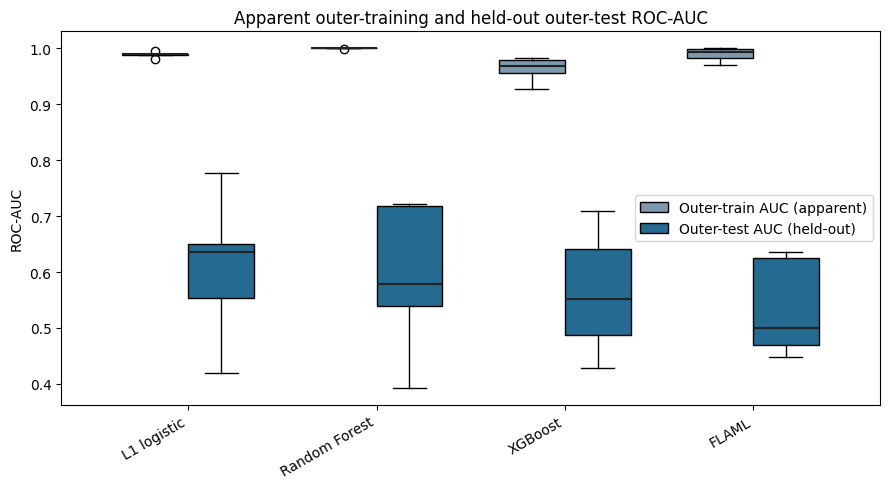

best_inner_score             roc_auc            \
                          mean       std      mean       std   
model                                                          
random_forest         0.663  0.030  0.590  0.137   
xgboost               0.661  0.030  0.564  0.113   
flaml_automl          0.660  0.040  0.536  0.088   
logreg_l1             0.603  0.049  0.607  0.132   

              balanced_accuracy            f1_macro           precision  \
                           mean       std      mean       std      mean   
model                                                                     
random_forest          0.552  0.125  0.539  0.118  0.670   
xgboost                0.531  0.145  0.504  0.157  0.598   
flaml_automl           0.456  0.035  0.433  0.051  0.577   
logreg_l1              0.511  0.129  0.488  0.149  0.617   

                           recall            
                    std      mean       std  
model                                        
random_forest  0.138  0.559  0.121  
xgboost        0.120  0.698  0.353  
flaml_automl   0.041  0.689  0.135  
logreg_l1      0.105  0.592  0.201

,model,roc_auc,balanced_accuracy,f1_macro,precision,recall,specificity,average_precision,brier_score
0,flaml_automl,0.545,0.459,0.449,0.580,0.691,0.227,0.690,0.252


--- Plotting ROC Curve ---


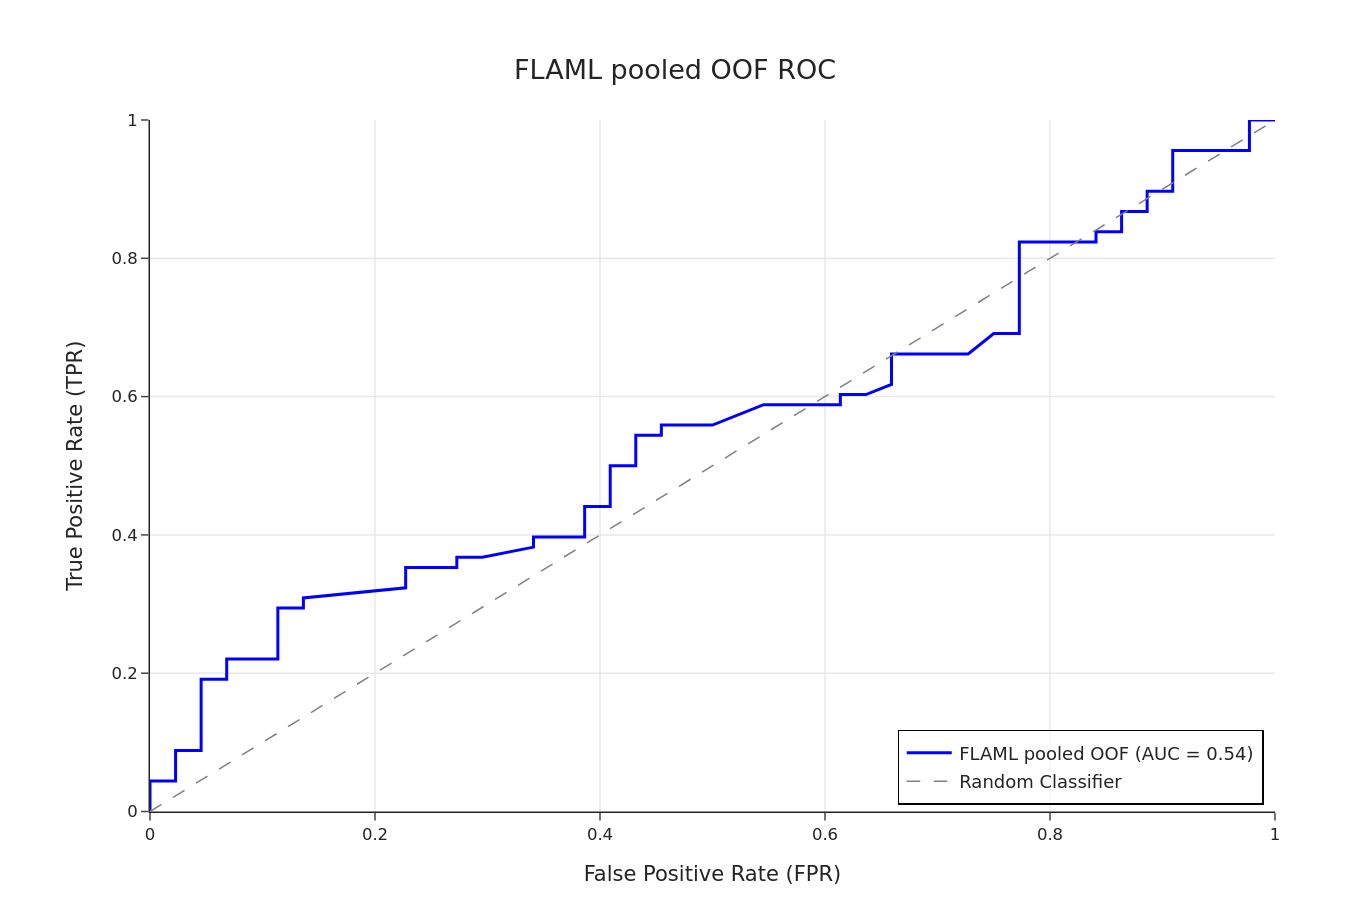

--- Plotting Precision–Recall Curve ---


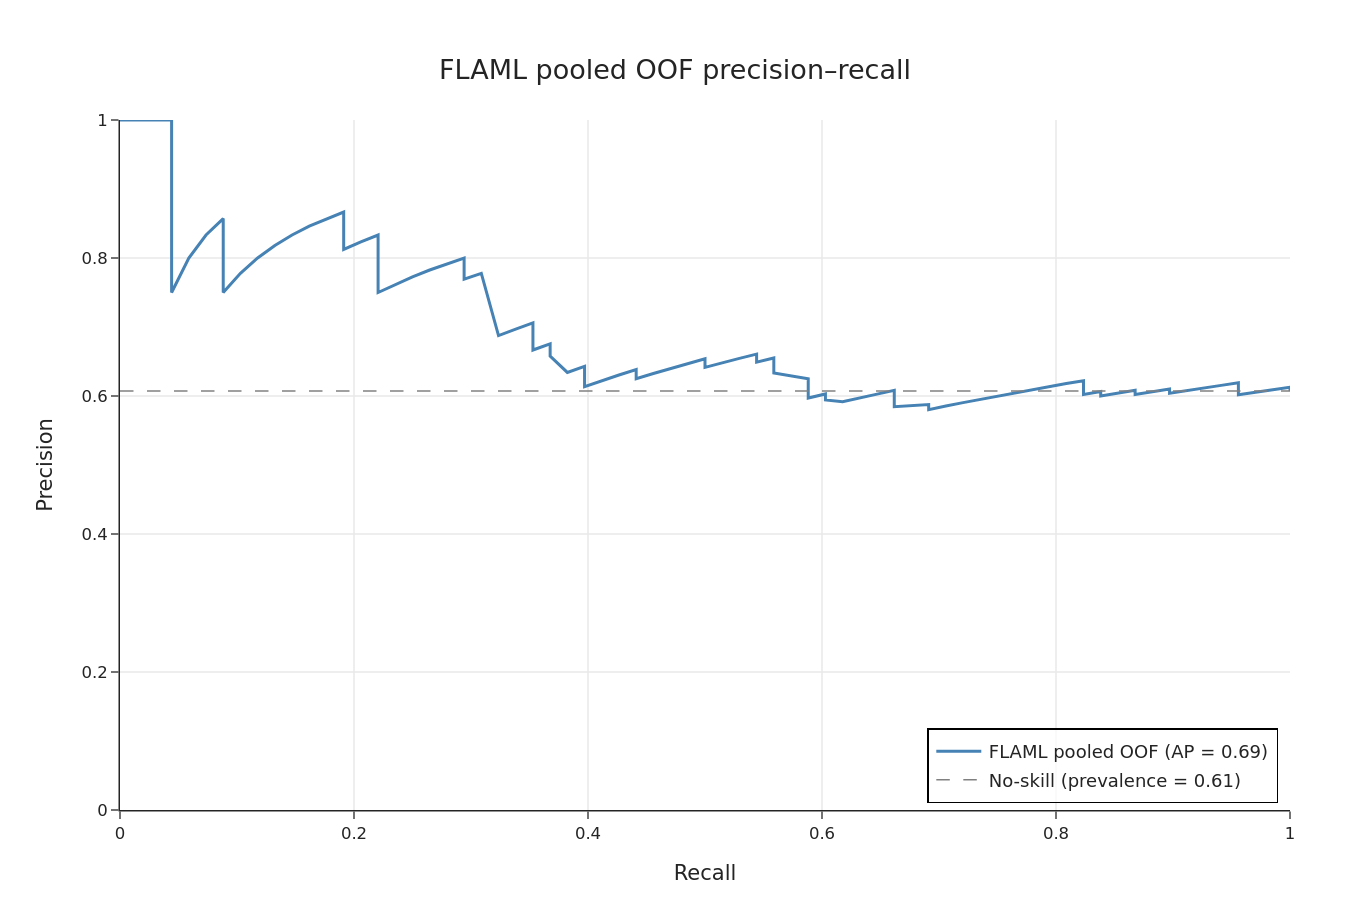

In [39]:
if flaml_predictions_df is not None:
    combined_test_results_df = pd.concat([results_test_df, flaml_results_test_df], ignore_index=True)
    combined_train_results_df = pd.concat([results_train_df, flaml_results_train_df], ignore_index=True)
    plot_train_test_boxplots_mutation(combined_train_results_df, combined_test_results_df, metric="roc_auc")
    flaml_model_selection_summary = combined_test_results_df.groupby("model")[[
        "best_inner_score", "roc_auc", "balanced_accuracy", "f1_macro", "precision", "recall"
    ]].agg(["mean", "std"]).sort_values(("best_inner_score", "mean"), ascending=False)
    thesis_display(flaml_model_selection_summary)
    flaml_model_selection_summary.to_csv(Path(output_dir) / "mutation_flaml_aligned_comparison.csv")
    flaml_pooled_df = pd.DataFrame([{"model": "flaml_automl", **mutation_pooled_oof_metrics(flaml_oof_df)}])
    thesis_display(flaml_pooled_df)
    flaml_pooled_df.to_csv(Path(output_dir) / "mutation_flaml_aligned_pooled_oof_metrics.csv", index=False)
    flaml_curves = [{"y_true": flaml_oof_df.y_true, "y_prob": flaml_oof_df.y_proba,
                     "label": "FLAML pooled OOF", "is_main_curve": True}]
    plot_roc_curves(flaml_curves, title="FLAML pooled OOF ROC", interactive=False)
    plot_precision_recall_curves(flaml_curves, title="FLAML pooled OOF precision–recall", interactive=False)
else:
    thesis_print("Comparison awaits aligned FLAML results.")


**Full availability (N=112).** Aligned FLAML achieved mean inner-CV macro-F1 of 0.6600, compared with 0.6627 for Random Forest, 0.6606 for XGBoost and 0.6025 for L1 logistic regression. Random Forest remains the selected manual family under the predefined mean inner-CV criterion.

Mean outer-fold ROC-AUC was 0.5357 for FLAML, compared with 0.5902 for Random Forest, 0.5637 for XGBoost and 0.6069 for L1. FLAML's pooled OOF ROC-AUC was 0.5446, balanced accuracy 0.4592, macro-F1 0.4488, average precision 0.6904 and Brier score 0.2521.

The similar inner scores did not translate into strong held-out performance. These descriptive comparisons do not establish superiority, given the small cohort, fold variability and different search spaces and computational budgets. Outer-test performance never determines the selected manual family.

## Full-cohort FLAML for exploratory gene comparison

The fresh full-cohort FLAML search used five-fold stratified internal CV, macro-F1 and a 120-second budget, matching the nested run's objective, inner-fold count and per-search budget. It selected Extra Trees with `n_estimators=4`, `max_features=0.014821729168218806`, `max_leaves=7` and `criterion='gini'`.

The fitted model supplies gene rankings for exploratory comparison only. It was obtained from a new search, not the most frequent outer-fold estimator or configuration. Its training and internal-CV scores are not unbiased performance estimates and do not replace aligned nested-CV results.

In [40]:
final_flaml_model = None
flaml_top_genes_df = None
if RUN_FULL_COHORT_FLAML:
    if flaml_predictions_df is None:
        raise ValueError("Complete or load aligned nested FLAML before full-cohort interpretation.")
    mutation_flaml_settings(FLAML_TIME_BUDGET_SECONDS, RANDOM_STATE)
    if FLAML_TIME_BUDGET_SECONDS != saved_flaml_budget:
        raise ValueError("Full-cohort FLAML must use the same budget as the aligned nested results.")
    final_flaml_model = tune_full_cohort_flaml_mutation(
        X, y, FLAML_TIME_BUDGET_SECONDS, random_state=RANDOM_STATE
    )
    thesis_print("Exploratory full-cohort estimator:", final_flaml_model.best_estimator)
    thesis_print("Exploratory configuration:", final_flaml_model.best_config)
    flaml_top_genes_df = extract_fitted_flaml_gene_rankings_mutation(final_flaml_model, X.columns, top_n=20)
    display_interpretation(flaml_top_genes_df)
    flaml_top_genes_df.to_csv(Path(output_dir) / "mutation_flaml_full_cohort_tuned_top_genes.csv", index=False)
else:
    thesis_print("Full-cohort FLAML interpretation skipped.")


Exploratory full-cohort estimator: extra_tree
Exploratory configuration: {'n_estimators': 4, 'max_features': np.float64(0.014821729168218806), 'max_leaves': 7, 'criterion': np.str_('gini')}


,gene,importance
0,ALPK3,0.0664
1,MUC6,0.0629
2,BOC,0.0573
3,TAAR5,0.0542
4,RENBP,0.0540
5,CDH23,0.0530
6,RALGDS,0.0500
7,MAP7D3,0.0475
8,SPATA20,0.0399
9,RNASET2,0.0381
